# SolarGuard
## Estimasi Daya Surya Berdasarkan Kondisi Cuaca untuk Prioritas Inspeksi

**Predictive Analytics — Cakrawala University | Kelompok 7**

| Nama | ID mahasiswa | Struktur kelompok |
|---|---|---|
| Titanio Yudista | 24120500031 | Ketua |
| Farisyah Aulia Hanum | 24120500027 | Anggota |
| Sayyid Abdul Aziz Haidar | 24120500005 | Anggota |

Laporan analitis ini mengikuti 13 bagian notebook pada panduan tugas. Semua angka hasil di bawah dihitung dari empat CSV lokal,
bukan hasil contoh. Jalankan **Restart Kernel / Runtime → Run All** dari folder proyek.
Dependensi tercatat di `requirements.txt`; instalasi opsional dari terminal: `pip install -r requirements.txt`.
Notebook tidak mengunduh data atau membutuhkan kredensial saat dijalankan.

**Status administratif:** pada 14 Oktober 2026, tim mengonfirmasi melalui percakapan
bahwa dataset sudah terdaftar di s.id/listdatapred02, berbeda dari kelompok lain,
dan bukan dataset UTS salah satu anggota. Ini konfirmasi tim, bukan verifikasi registry
secara independen; simpan bukti entri bersama paket tugas. Kontribusi aktual setiap anggota
masih perlu dicatat. Identitas anggota bukan
klaim bahwa masing-masing telah mengerjakan kode ini. Lihat `CONTRIBUTIONS.md`.

## 1. Gambaran umum proyek

**Tema:** Energi dan Lingkungan. **Pemangku kepentingan:** Manajer Operasional Pembangkit Surya / COO.
Daya mentah inverter berubah bersama cuaca; membandingkan daya tanpa kondisi cuaca
dapat menghasilkan prioritas inspeksi yang keliru. Kita menguji estimasi output yang
diharapkan untuk mendukung pemeriksaan operator.

**Pertanyaan prediktif:** Dengan sensor cuaca yang tersedia pada waktu t, identitas
pembangkit/inverter, dan waktu, seberapa akurat DC_POWER pada t dapat diestimasi pada hari yang
lebih baru untuk inverter yang sudah dikenal?

**Jenis tugas:** regresi. **Target:** DC_POWER, satuan asli dataset (satuan fisik belum terverifikasi).
**Unit analisis:** satu inverter pada satu waktu pengamatan, dengan interval nominal 15 menit.
**Horizon prediksi:** 0; sensor cuaca t harus tersedia saat estimasi. DC_POWER aktual baru
dipakai sesudah estimasi untuk menghitung selisih. Penelitian ini tidak menguji peramalan
hari berikutnya, klasifikasi kerusakan, waktu peringatan sebelum kegagalan, maupun
penerapan pada pembangkit baru.

Tujuan SolarGuard adalah uji coba penentuan prioritas inspeksi: daya estimasi dibandingkan
dengan daya aktual, kemudian operator memeriksa selisih yang menetap. Tanpa catatan
pemeliharaan dan kegagalan, selisih belum membuktikan kerusakan atau manfaat ekonomi.
Data publik berisi identitas alat, tanpa identitas pribadi yang terlihat; risiko salah
prioritas dan peringatan keliru tetap harus ditangani melalui pemeriksaan manusia.

In [1]:
from pathlib import Path
import os
import sys
import json
import hashlib
import platform
import time
from datetime import datetime, timezone
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from sklearn.base import clone, BaseEstimator, RegressorMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV, ParameterGrid
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.inspection import permutation_importance
from threadpoolctl import threadpool_limits

RUN_START = time.perf_counter()
SEED = 42
np.random.seed(SEED)
DATA_DIR = Path('data')
OUT = Path('outputs')
FIG = OUT / 'figures'
FIG.mkdir(parents=True, exist_ok=True)
# Single search worker + bounded estimator threads avoids nested parallelism.
WORKERS = min(4, os.cpu_count() or 1)
thread_limit = threadpool_limits(limits=WORKERS)
sns.set_theme(style='whitegrid', palette='colorblind', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 160, 'axes.titlesize': 12})
pd.set_option('display.max_columns', 20)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')

def show_table(frame, name):
    frame.to_csv(OUT / f'{name}.csv', index=False)
    display(frame)

def save_plot(name):
    plt.tight_layout()
    plt.savefig(FIG / f'{name}.png', bbox_inches='tight')
    plt.show()
    plt.close()

def note(text):
    display(Markdown(text))

def metrics(y, pred):
    y, pred = np.asarray(y), np.asarray(pred)
    return {'n': len(y), 'MAE': mean_absolute_error(y, pred),
            'RMSE': np.sqrt(mean_squared_error(y, pred)),
            'R2': r2_score(y, pred) if len(y) > 1 and np.var(y) > 0 else np.nan,
            'bias_actual_minus_pred': float(np.mean(y - pred))}

environment = {p: version(p) for p in ['numpy', 'pandas', 'scikit-learn',
    'matplotlib', 'seaborn', 'scipy', 'nbformat', 'nbclient', 'ipykernel', 'threadpoolctl']}
display(pd.Series({'Python': sys.version.split()[0], 'OS': platform.platform(),
                   'CPUs available': os.cpu_count(), 'threads used': WORKERS, **environment}))

Python                                                 3.12.10
OS                Linux-7.0.0-38-generic-x86_64-with-glibc2.39
CPUs available                                               8
threads used                                                 4
numpy                                                    2.5.2
pandas                                                   3.0.5
scikit-learn                                             1.9.0
matplotlib                                              3.11.1
seaborn                                                 0.13.2
scipy                                                   1.18.0
nbformat                                                5.11.1
nbclient                                                0.11.0
ipykernel                                                7.3.0
threadpoolctl                                            3.6.0
dtype: object

## 2. Deskripsi dataset

Sumber: [Solar Power Generation Data](https://www.kaggle.com/datasets/anikannal/solar-power-generation-data),
diunggah Ani Kannal, **versi 1** (rilis 18 Agustus 2020), diakses 14 Oktober 2026.
Salinan metadata dari layanan publik tersedia pada `data/source_metadata.json`.
Deskripsi repositori menyebut dua pembangkit di India selama 34 hari, pengukuran daya
pada tingkat inverter, dan satu rangkaian sensor pada tingkat pembangkit. Pemilik
fasilitas atau pengumpul data asli tidak diidentifikasi dalam metadata tersebut.
Lisensi tercantum **Data files © Original Authors**; nama lisensi ini dikutip sesuai sumber
dan bukan pernyataan lisensi terbuka tanpa batas. Tim perlu memastikan ketentuan penggunaan
dan distribusi untuk pengumpulan tugas; akses publik tidak menggantikan pemeriksaan izin.

Satuan daya, temperatur, dan iradiasi tidak dijelaskan dalam metadata yang diperoleh.
Grafik memakai **satuan asli dataset**, tanpa koreksi faktor skala yang tidak terverifikasi.
Waktu pengamatan diperlakukan sebagai waktu lokal sumber tanpa zona waktu yang dikonfirmasi;
tidak dikonversi ke WIB. WIB hanya untuk administrasi tugas.

| Kolom | Definisi / peran |
|---|---|
| DATE_TIME | Waktu pengamatan; format eksplisit berbeda pada data daya Plant 1 |
| PLANT_ID | ID pembangkit asli; kategori, bukan besaran numerik |
| SOURCE_KEY pada data daya | ID inverter; namanya diubah menjadi INVERTER_ID |
| SOURCE_KEY pada data cuaca | ID sensor; diubah menjadi SENSOR_ID; tidak digunakan sebagai kunci penggabungan |
| DC_POWER | Target daya DC pada waktu t, dalam satuan asli |
| AC_POWER | Daya AC bersamaan; proksi target, hanya untuk audit data pengembangan |
| DAILY_YIELD / TOTAL_YIELD | Hasil energi kumulatif; dikeluarkan dari fitur penelitian ini |
| AMBIENT_TEMPERATURE | Temperatur lingkungan pada t, fitur sensor |
| MODULE_TEMPERATURE | Temperatur modul pada t, fitur sensor |
| IRRADIATION | Iradiasi pada t; fitur dan penentu kelayakan pengamatan siang |

Enam calon prediktor tersedia: tiga sensor cuaca, waktu pengamatan, ID pembangkit, dan ID inverter.
Ukuran aktual dan nilai hash di bawah menjadi bukti kelayakan serta identitas versi data yang digunakan.

In [2]:
FILES = {f'Plant_{p}_{kind}_Data.csv':
         ('%d-%m-%Y %H:%M' if p == 1 and kind == 'Generation' else '%Y-%m-%d %H:%M:%S')
         for p in [1, 2] for kind in ['Generation', 'Weather_Sensor']}
raw, parsed, manifest_rows, schema_rows = {}, {}, [], []
for name, fmt in FILES.items():
    path = DATA_DIR / name
    if not path.exists():
        raise FileNotFoundError(f'Missing exact dataset: {path}. See DATA_SOURCE.md.')
    df = pd.read_csv(path)
    raw[name] = df.copy()
    for col in df:
        schema_rows.append({'file': name, 'column': col, 'dtype_raw': str(df[col].dtype),
                            'missing': int(df[col].isna().sum())})
    df['DATE_TIME'] = pd.to_datetime(df['DATE_TIME'], format=fmt, errors='coerce')
    parsed[name] = df
    manifest_rows.append({'file': name, 'rows': len(df), 'columns': len(df.columns),
        'start': str(df.DATE_TIME.min()), 'end': str(df.DATE_TIME.max()),
        'days': df.DATE_TIME.dt.normalize().nunique(), 'plants': df.PLANT_ID.nunique(),
        'source_keys': df.SOURCE_KEY.nunique(), 'datetime_parse_failures': int(df.DATE_TIME.isna().sum()),
        'sha256': hashlib.sha256(path.read_bytes()).hexdigest(), 'bytes': path.stat().st_size})
manifest = pd.DataFrame(manifest_rows)
show_table(manifest.drop(columns=['sha256']), 'dataset_dimensions')
show_table(pd.DataFrame(schema_rows), 'schema_missingness')
(OUT / 'data_manifest.json').write_text(json.dumps(manifest_rows, indent=2))
display(manifest[['file', 'sha256']])
assert sum(len(df) for n, df in parsed.items() if 'Generation' in n) >= 1000
assert all(df.DATE_TIME.notna().all() for df in parsed.values())
for name, df in parsed.items():
    print(name)
    display(df.head(2))

,file,rows,columns,start,end,days,plants,source_keys,datetime_parse_failures,bytes
0,Plant_1_Generation_Data.csv,68778,7,2020-05-15 00:00:00,2020-06-17 23:45:00,34,1,22,0,4839076
1,Plant_1_Weather_Sensor_Data.csv,3182,6,2020-05-15 00:00:00,2020-06-17 23:45:00,34,1,1,0,287847
2,Plant_2_Generation_Data.csv,67698,7,2020-05-15 00:00:00,2020-06-17 23:45:00,34,1,22,0,5805157
3,Plant_2_Weather_Sensor_Data.csv,3259,6,2020-05-15 00:00:00,2020-06-17 23:45:00,34,1,1,0,301443


,file,column,dtype_raw,missing
0,Plant_1_Generation_Data.csv,DATE_TIME,str,0
1,Plant_1_Generation_Data.csv,PLANT_ID,int64,0
2,Plant_1_Generation_Data.csv,SOURCE_KEY,str,0
3,Plant_1_Generation_Data.csv,DC_POWER,float64,0
4,Plant_1_Generation_Data.csv,AC_POWER,float64,0
5,Plant_1_Generation_Data.csv,DAILY_YIELD,float64,0
6,Plant_1_Generation_Data.csv,TOTAL_YIELD,float64,0
7,Plant_1_Weather_Sensor_Data.csv,DATE_TIME,str,0
8,Plant_1_Weather_Sensor_Data.csv,PLANT_ID,int64,0
9,Plant_1_Weather_Sensor_Data.csv,SOURCE_KEY,str,0


,file,sha256
0,Plant_1_Generation_Data.csv,882f75f1c295946633617646cc92343ddb6fb821a2546c...
1,Plant_1_Weather_Sensor_Data.csv,91325041328745c288cb809aebd8b1b59cde5428450090...
2,Plant_2_Generation_Data.csv,9b735e9278774d4d1dd4601047315ef50b3793244d8924...
3,Plant_2_Weather_Sensor_Data.csv,cafd80885a51b88521b3301cffa4e4f013e2516fcb3478...


Plant_1_Generation_Data.csv


,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD
0,2020-05-15,4135001,1BY6WEcLGh8j5v7,0.0000,0.0000,0.0000,"6,259,559.0000"
1,2020-05-15,4135001,1IF53ai7Xc0U56Y,0.0000,0.0000,0.0000,"6,183,645.0000"


...

,DATE_TIME,PLANT_ID,SOURCE_KEY,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,2020-05-15 00:00:00,4135001,HmiyD2TTLFNqkNe,25.1843,22.8575,0.0000
1,2020-05-15 00:15:00,4135001,HmiyD2TTLFNqkNe,25.0846,22.7617,0.0000


Plant_2_Generation_Data.csv


,DATE_TIME,PLANT_ID,SOURCE_KEY,DC_POWER,AC_POWER,DAILY_YIELD,TOTAL_YIELD
0,2020-05-15,4136001,4UPUqMRk7TRMgml,0.0000,0.0000,"9,425.0000","2,429,011.0000"
1,2020-05-15,4136001,81aHJ1q11NBPMrL,0.0000,0.0000,0.0000,"1,215,278,736.0000"


Plant_2_Weather_Sensor_Data.csv


,DATE_TIME,PLANT_ID,SOURCE_KEY,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE,IRRADIATION
0,2020-05-15 00:00:00,4136001,iq8k7ZNt4Mwm3w0,27.0048,25.0608,0.0000
1,2020-05-15 00:15:00,4136001,iq8k7ZNt4Mwm3w0,26.8808,24.4219,0.0000


## 3. Penilaian kualitas data

Audit seluruh data pada bagian 2–4 dibatasi pada struktur kolom, kunci, waktu pengamatan,
nilai hilang, dan aturan nilai tidak valid yang telah ditentukan. Statistik distribusi
target, korelasi, skala, pencilan, dan keputusan pemodelan hanya menggunakan data
pengembangan setelah pembagian. Target yang hilang tidak diisi, dan nilai nol pada siang
hari tidak dihapus karena dapat menjadi sinyal operasional. Temperatur negatif tidak
otomatis tidak valid. Nilai tak hingga diperlakukan sebagai nilai hilang atau tidak valid.
Baris yang identik dapat dihapus; kunci ganda dengan isi bertentangan menghentikan eksekusi
agar tidak memilih catatan secara sembarang.

In [3]:
audit_rows, cadence_rows, coverage_rows = [], [], []
for name, df in parsed.items():
    is_gen = 'Generation' in name
    key = ['PLANT_ID', 'SOURCE_KEY', 'DATE_TIME'] if is_gen else ['PLANT_ID', 'DATE_TIME']
    numeric = df.select_dtypes(include='number')
    audit_rows.append({'file': name, 'exact_duplicates': int(df.duplicated().sum()),
        'duplicate_keys_after_exact_drop': int(df.drop_duplicates().duplicated(key).sum()),
        'missing_cells': int(df.isna().sum().sum()),
        'infinite_numeric_cells': int(np.isinf(numeric.to_numpy()).sum()),
        'missing_key_rows': int(df[key].isna().any(axis=1).sum()),
        'negative_DC_POWER': int((df.DC_POWER < 0).sum()) if is_gen else 0,
        'negative_IRRADIATION': int((df.IRRADIATION < 0).sum()) if not is_gen else 0})
    for (plant, source), part in df.groupby(['PLANT_ID', 'SOURCE_KEY']):
        ts = part.DATE_TIME.drop_duplicates().sort_values()
        delta = ts.diff().dropna().dt.total_seconds().div(60)
        cadence_rows.append({'file': name, 'plant': plant, 'source': source,
            'timestamps': len(ts), 'median_interval_minutes': delta.median(),
            'intervals_not_15_minutes': int(delta.ne(15).sum()),
            'max_interval_minutes': delta.max()})
        expected = int((ts.max() - ts.min()).total_seconds() / 900) + 1
        coverage_rows.append({'file': name, 'plant': plant, 'source': source,
            'observed': len(ts), 'expected_between_endpoints': expected,
            'absent_intervals': expected - len(ts), 'coverage_pct': 100 * len(ts) / expected})
audit = pd.DataFrame(audit_rows)
show_table(audit, 'raw_quality_audit')
cadence = pd.DataFrame(cadence_rows)
show_table(cadence.groupby('file', as_index=False).agg(
    median_interval_minutes=('median_interval_minutes', 'median'),
    non_15_minute_intervals=('intervals_not_15_minutes', 'sum'),
    max_gap_minutes=('max_interval_minutes', 'max')), 'cadence_summary')
coverage = pd.DataFrame(coverage_rows)
show_table(coverage.groupby('file', as_index=False).agg(
    absent_intervals=('absent_intervals', 'sum'),
    min_coverage_pct=('coverage_pct', 'min'), mean_coverage_pct=('coverage_pct', 'mean')),
    'coverage_summary')
coverage.to_csv(OUT / 'coverage_per_source.csv', index=False)
assert (audit.duplicate_keys_after_exact_drop == 0).all(), 'Conflicting keys require review'
assert (audit.missing_key_rows == 0).all(), 'Missing IDs/timestamps require review'

,file,exact_duplicates,duplicate_keys_after_exact_drop,missing_cells,infinite_numeric_cells,missing_key_rows,negative_DC_POWER,negative_IRRADIATION
0,Plant_1_Generation_Data.csv,0,0,0,0,0,0,0
1,Plant_1_Weather_Sensor_Data.csv,0,0,0,0,0,0,0
2,Plant_2_Generation_Data.csv,0,0,0,0,0,0,0
3,Plant_2_Weather_Sensor_Data.csv,0,0,0,0,0,0,0


,file,median_interval_minutes,non_15_minute_intervals,max_gap_minutes
0,Plant_1_Generation_Data.csv,15.0000,332,540.0000
1,Plant_1_Weather_Sensor_Data.csv,15.0000,8,435.0000
2,Plant_2_Generation_Data.csv,15.0000,120,"12,630.0000"
3,Plant_2_Weather_Sensor_Data.csv,15.0000,5,30.0000


,file,absent_intervals,min_coverage_pct,mean_coverage_pct
0,Plant_1_Generation_Data.csv,3026,95.2147,95.7857
1,Plant_1_Weather_Sensor_Data.csv,82,97.4877,97.4877
2,Plant_2_Generation_Data.csv,4110,72.1507,94.2764
3,Plant_2_Weather_Sensor_Data.csv,5,99.8468,99.8468


### Daftar risiko kebocoran data

| Kolom atau komponen | Ketersediaan / keputusan |
|---|---|
| Cuaca pada t, ID, waktu | Diizinkan untuk estimasi t, dengan asumsi sensor diterima tepat waktu |
| AC_POWER pada t | Dikeluarkan; proksi daya bersamaan membuat estimasi tidak bermakna untuk pemantauan |
| DAILY_YIELD / TOTAL_YIELD | Dikeluarkan; kumulatif terkait daya, dengan pengaturan ulang dan ketersediaan yang belum memadai untuk ruang lingkup ini |
| DC_POWER | Target, tidak pernah masuk masukan prapemrosesan |
| SENSOR_ID | Tidak digunakan: identitas sensor bukan identitas inverter |
| Statistik imputasi, pengodean, dan penskalaan | Dipelajari hanya pada bagian pelatihan setiap lipatan validasi melalui pipeline |
| Nilai tertunda atau nilai masa depan | Tidak digunakan; horizon 0 tanpa interpolasi yang memakai masa depan |

Hasil energi kumulatif tidak otomatis mengandung informasi masa depan; alasan
pengeluarannya adalah hubungan dengan daya dan ketidakjelasan waktu ketersediaannya
untuk penggunaan yang dipilih.

## 4. Persiapan data

Data daya dan cuaca digabung berdasarkan pembangkit dan waktu pengamatan, dengan
validasi hubungan banyak-ke-satu. ID pembangkit asli disimpan, sedangkan ID inverter
dipisahkan dari ID sensor. Iradiasi negatif diubah menjadi nilai hilang dan tidak
memenuhi syarat analisis. Target negatif atau tidak berhingga dikeluarkan; nilai hilang
pada fitur lain ditangani melalui pipeline. Pengamatan siang ditentukan sebelum melihat
hasil: iradiasi valid > 0. Iradiasi yang hilang dilaporkan sebagai data tidak tersedia,
bukan malam. Tidak dilakukan pembatasan nilai target, pengisian dari pengamatan
sebelumnya, koreksi skala, atau pembuangan pencilan yang valid.

In [4]:
generations, weathers = [], []
for name, frame in parsed.items():
    df = frame.drop_duplicates().copy()
    df['PLANT_ID'] = df['PLANT_ID'].astype(str)
    df['SOURCE_KEY'] = df['SOURCE_KEY'].astype(str)
    if 'Generation' in name:
        generations.append(df.rename(columns={'SOURCE_KEY': 'INVERTER_ID'}))
    else:
        weathers.append(df.rename(columns={'SOURCE_KEY': 'SENSOR_ID'}))
gen = pd.concat(generations, ignore_index=True)
weather = pd.concat(weathers, ignore_index=True)
assert not gen.duplicated(['PLANT_ID', 'INVERTER_ID', 'DATE_TIME']).any()
assert not weather.duplicated(['PLANT_ID', 'DATE_TIME']).any()
merged = gen.merge(weather, on=['PLANT_ID', 'DATE_TIME'], how='left',
                   validate='many_to_one', indicator=True)
assert len(merged) == len(gen)
join_audit = merged.groupby('PLANT_ID', observed=True).agg(
    generation_rows=('DC_POWER', 'size'),
    matched_weather_rows=('_merge', lambda s: int(s.eq('both').sum())),
    missing_irradiation=('IRRADIATION', lambda s: int(s.isna().sum())))
join_audit['weather_match_pct'] = 100 * join_audit.matched_weather_rows / join_audit.generation_rows
show_table(join_audit.reset_index(), 'join_audit')
sensor_cols = ['IRRADIATION', 'AMBIENT_TEMPERATURE', 'MODULE_TEMPERATURE']
merged[sensor_cols] = merged[sensor_cols].replace([np.inf, -np.inf], np.nan)
merged.loc[merged.IRRADIATION < 0, 'IRRADIATION'] = np.nan
valid_target = np.isfinite(merged.DC_POWER) & merged.DC_POWER.ge(0)
valid_irr = merged.IRRADIATION.notna()
eligible = valid_target & valid_irr & merged.IRRADIATION.gt(0)
flow = pd.DataFrame([
    {'stage': 'raw generation', 'rows': len(gen)},
    {'stage': 'left join (no multiplication)', 'rows': len(merged)},
    {'stage': 'valid observed target', 'rows': int(valid_target.sum())},
    {'stage': 'valid target + available irradiation', 'rows': int((valid_target & valid_irr).sum())},
    {'stage': 'eligible daytime; zeros retained', 'rows': int(eligible.sum())}])
show_table(flow, 'cleaning_row_flow')
exclusions = merged.assign(invalid_target=~valid_target, unavailable_irr=~valid_irr,
    non_daytime=valid_irr & merged.IRRADIATION.le(0), eligible=eligible).groupby('PLANT_ID').agg(
    raw_rows=('DC_POWER', 'size'), invalid_target=('invalid_target', 'sum'),
    unavailable_irr=('unavailable_irr', 'sum'), non_daytime=('non_daytime', 'sum'),
    eligible_rows=('eligible', 'sum'))
exclusions['eligible_pct'] = 100 * exclusions.eligible_rows / exclusions.raw_rows
show_table(exclusions.reset_index(), 'eligibility_by_plant')
# Split dates come from structural timestamps before inspecting target distributions.
all_dates = np.sort(merged.DATE_TIME.dt.normalize().unique())
cut = int(len(all_dates) * 0.8)
dev_dates, test_dates = all_dates[:cut], all_dates[cut:]
panel = merged.loc[eligible].copy()
panel['DATE'] = panel.DATE_TIME.dt.normalize()
dev = panel.loc[panel.DATE.isin(dev_dates)].sort_values(
    ['DATE_TIME', 'PLANT_ID', 'INVERTER_ID']).reset_index(drop=True)
test = panel.loc[panel.DATE.isin(test_dates)].sort_values(
    ['DATE_TIME', 'PLANT_ID', 'INVERTER_ID']).reset_index(drop=True)
assert dev.DATE_TIME.max() < test.DATE_TIME.min()
assert set(dev.DATE).isdisjoint(test.DATE)
assert len(dev) >= 1000
show_table(pd.DataFrame([{'partition': name, 'rows': len(d), 'days': d.DATE.nunique(),
    'start': d.DATE_TIME.min(), 'end': d.DATE_TIME.max(),
    'plants': d.PLANT_ID.nunique(), 'inverters': d.INVERTER_ID.nunique()}
    for name, d in [('development', dev), ('locked test', test)]]), 'holdout_split')
show_table(dev[sensor_cols + ['DC_POWER']].isna().sum().rename('missing_development').reset_index(),
           'development_missing_features')
note(f'**Persiapan data:** {eligible.sum():,}/{len(merged):,} baris data daya memenuhi syarat '
     f'({100 * eligible.mean():.2f}%). Baris tanpa pasangan cuaca: {merged._merge.eq("left_only").sum():,}. '
     'Cakupan hanya berlaku pada catatan yang diamati; interval daya yang hilang tidak direkonstruksi.')

,PLANT_ID,generation_rows,matched_weather_rows,missing_irradiation,weather_match_pct
0,4135001,68778,68774,4,99.9942
1,4136001,67698,67698,0,100.0000


,stage,rows
0,raw generation,136476
1,left join (no multiplication),136476
2,valid observed target,136476
3,valid target + available irradiation,136472
4,eligible daytime; zeros retained,77098


,PLANT_ID,raw_rows,invalid_target,unavailable_irr,non_daytime,eligible_rows,eligible_pct
0,4135001,68778,0,4,30398,38376,55.7969
1,4136001,67698,0,0,28976,38722,57.1981


,partition,rows,days,start,end,plants,inverters
0,development,60510,27,2020-05-15 05:45:00,2020-06-10 21:15:00,2,44
1,locked test,16588,7,2020-06-11 02:45:00,2020-06-17 18:45:00,2,44


,index,missing_development
0,IRRADIATION,0
1,AMBIENT_TEMPERATURE,0
2,MODULE_TEMPERATURE,0
3,DC_POWER,0


**Persiapan data:** 77,098/136,476 baris data daya memenuhi syarat (56.49%). Baris tanpa pasangan cuaca: 4. Cakupan hanya berlaku pada catatan yang diamati; interval daya yang hilang tidak direkonstruksi.

### Audit skala, target, dan pencilan pada data pengembangan

AC_POWER dipertahankan hanya dalam tabel audit dan secara eksplisit dikeluarkan dari
masukan model. Rasio DC/AC di bawah tidak cukup untuk menentukan faktor koreksi.
Satuan DC_POWER asli dipertahankan; model gabungan menggunakan identitas pembangkit,
kemudian galat dilaporkan per pembangkit. Tujuan utama adalah MAE gabungan pada skala
asli, dihitung sebagai rata-rata MAE setiap lipatan validasi. Tolok ukur ini memberi
bobot yang sama pada setiap lipatan; di dalam lipatan, setiap pengamatan berbobot sama.
Karena ukuran lipatan berbeda, bobot setiap baris tidak persis sama pada seluruh data
pengembangan. Skor secara numerik didominasi pembangkit dengan skala lebih besar.
Nilainya bukan kerugian fisik atau tujuan ekonomi yang
sebanding antar pembangkit. Batas ini ditetapkan sebelum perbandingan kandidat;
MAE per pembangkit dan MAE yang dinormalisasi terhadap rata-rata target data
pengembangan masing-masing pembangkit menjadi bukti pelengkap.

In [5]:
scale_audit = dev.groupby('PLANT_ID').agg(n=('DC_POWER', 'size'), mean_dc=('DC_POWER', 'mean'),
    median_dc=('DC_POWER', 'median'), max_dc=('DC_POWER', 'max'),
    mean_ac=('AC_POWER', 'mean'), daytime_zero=('DC_POWER', lambda s: int(s.eq(0).sum())))
ratios = dev.loc[(dev.DC_POWER > 0) & (dev.AC_POWER > 0)].assign(
    DC_AC_ratio=lambda x: x.DC_POWER / x.AC_POWER).groupby('PLANT_ID').DC_AC_ratio.median()
scale_audit['median_DC_AC_ratio'] = ratios
show_table(scale_audit.reset_index(), 'development_scale_audit')
outlier_rows = []
for plant, part in dev.groupby('PLANT_ID'):
    for col in ['DC_POWER'] + sensor_cols:
        s = part[col].dropna()
        q1, q3 = s.quantile([0.25, 0.75])
        iqr = q3 - q1
        outlier_rows.append({'plant': plant, 'feature': col, 'min': s.min(), 'max': s.max(),
            'q01': s.quantile(.01), 'q99': s.quantile(.99),
            'IQR_flag_count': int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()),
            'treatment': 'retain; diagnostic flag only'})
show_table(pd.DataFrame(outlier_rows), 'development_outlier_audit')
dev_full = merged.loc[merged.DATE_TIME.dt.normalize().isin(dev_dates)].copy()
dev_full['light'] = np.where(dev_full.IRRADIATION.isna(), 'unavailable',
                    np.where(dev_full.IRRADIATION > 0, 'daytime', 'non-daytime'))
show_table(dev_full.groupby(['PLANT_ID', 'light']).agg(n=('DC_POWER', 'size'),
    target_mean=('DC_POWER', 'mean'), zeros=('DC_POWER', lambda s: int(s.eq(0).sum()))).reset_index(),
    'development_day_night_target')
note('**Skala yang diamati:** ' + '; '.join(f'Plant {p}: median rasio DC/AC positif '
    f'{ratios.loc[p]:.3f}' for p in ratios.index) +
    '. Perbedaan antar pembangkit tidak dikoreksi tanpa metadata satuan/kapasitas yang dapat dipercaya. '
    'Semua nilai ekstrem yang valid dan nilai nol pada siang hari dipertahankan.')

,PLANT_ID,n,mean_dc,median_dc,max_dc,mean_ac,daytime_zero,median_DC_AC_ratio
0,4135001,30280,"5,788.8329","5,850.1339","14,413.4286",566.0426,1161,10.2219
1,4136001,30230,453.6549,365.1767,"1,420.9333",443.5689,5642,1.0224


,plant,feature,min,max,q01,q99,IQR_flag_count,treatment
0,4135001,DC_POWER,0.0000,"14,413.4286",0.0000,"13,162.6536",0,retain; diagnostic flag only
1,4135001,IRRADIATION,0.0000,1.1511,0.0002,1.0366,0,retain; diagnostic flag only
2,4135001,AMBIENT_TEMPERATURE,20.3985,35.2525,21.2906,34.3101,0,retain; diagnostic flag only
3,4135001,MODULE_TEMPERATURE,18.2423,65.5457,19.6510,61.5756,0,retain; diagnostic flag only
4,4136001,DC_POWER,0.0000,"1,420.9333",0.0000,"1,301.7624",0,retain; diagnostic flag only
5,4136001,IRRADIATION,0.0000,1.0988,0.0000,0.9896,0,retain; diagnostic flag only
6,4136001,AMBIENT_TEMPERATURE,21.2269,39.1816,22.9058,37.8752,0,retain; diagnostic flag only
7,4136001,MODULE_TEMPERATURE,20.2956,66.6360,21.3592,62.2064,0,retain; diagnostic flag only


,PLANT_ID,light,n,target_mean,zeros
0,4135001,daytime,30280,"5,788.8329",1161
1,4135001,non-daytime,23754,0.0000,23754
2,4135001,unavailable,4,"7,424.5000",0
3,4136001,daytime,30230,453.6549,5642
4,4136001,non-daytime,22684,0.0008,22670


**Skala yang diamati:** Plant 4135001: median rasio DC/AC positif 10.222; Plant 4136001: median rasio DC/AC positif 1.022. Perbedaan antar pembangkit tidak dikoreksi tanpa metadata satuan/kapasitas yang dapat dipercaya. Semua nilai ekstrem yang valid dan nilai nol pada siang hari dipertahankan.

## 5. Analisis eksploratif data

Seluruh analisis eksploratif di bawah hanya menggunakan data pengembangan. Histogram
dan diagram kotak merangkum variasi; diagram pencar dan korelasi dalam tiap pembangkit
menilai hubungan sensor; profil waktu mendasari pengodean waktu siklis. Perbedaan
inverter bersifat deskriptif dan dapat mencerminkan cakupan pengamatan, kapasitas,
atau konfigurasi peralatan. Perbedaan tersebut tidak mendiagnosis kerusakan.

,PLANT_ID,level_1,count,mean,std,min,25%,50%,75%,max
0,4135001,DC_POWER,"30,280.0000","5,788.8329","3,952.6292",0.0000,"2,048.3170","5,850.1339","9,040.5000","14,413.4286"
1,4135001,IRRADIATION,"30,280.0000",0.4310,0.3013,0.0000,0.1505,0.4241,0.6697,1.1511
2,4135001,AMBIENT_TEMPERATURE,"30,280.0000",27.8527,3.3507,20.3985,25.2504,27.9888,30.3105,35.2525
3,4135001,MODULE_TEMPERATURE,"30,280.0000",40.0524,11.8070,18.2423,29.5816,41.0341,49.4563,65.5457
4,4136001,DC_POWER,"30,230.0000",453.6549,421.9083,0.0000,36.1589,365.1767,803.7593,"1,420.9333"
5,4136001,IRRADIATION,"30,230.0000",0.4313,0.3274,0.0000,0.0985,0.4053,0.7371,1.0988
6,4136001,AMBIENT_TEMPERATURE,"30,230.0000",30.4973,4.1405,21.2269,27.0207,30.7858,33.8088,39.1816
7,4136001,MODULE_TEMPERATURE,"30,230.0000",40.4007,11.6307,20.2956,30.2103,40.4721,50.5748,66.6360


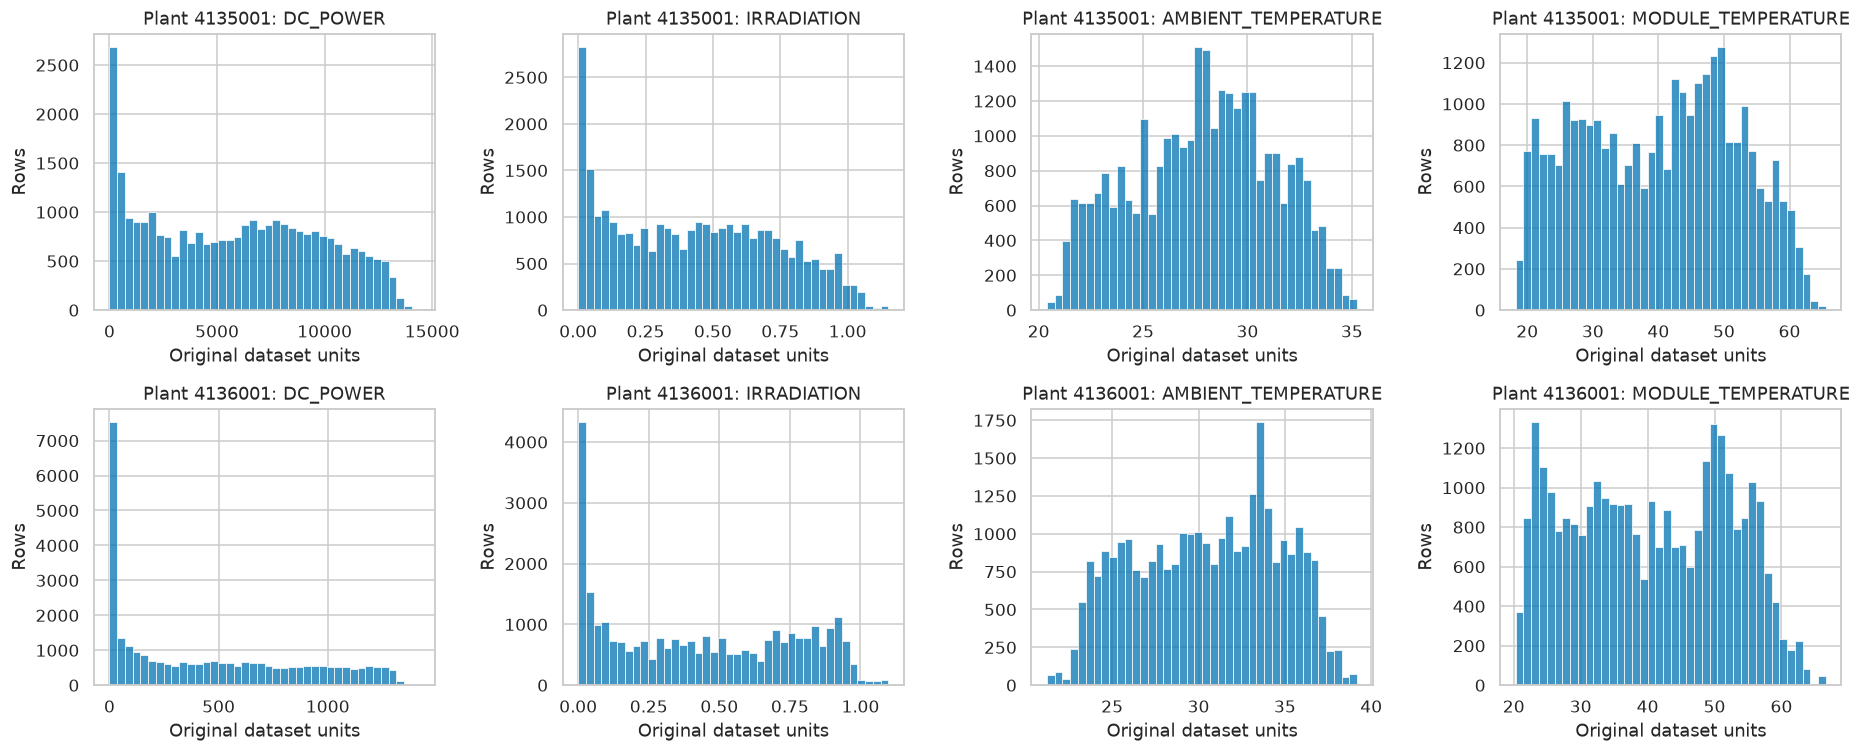

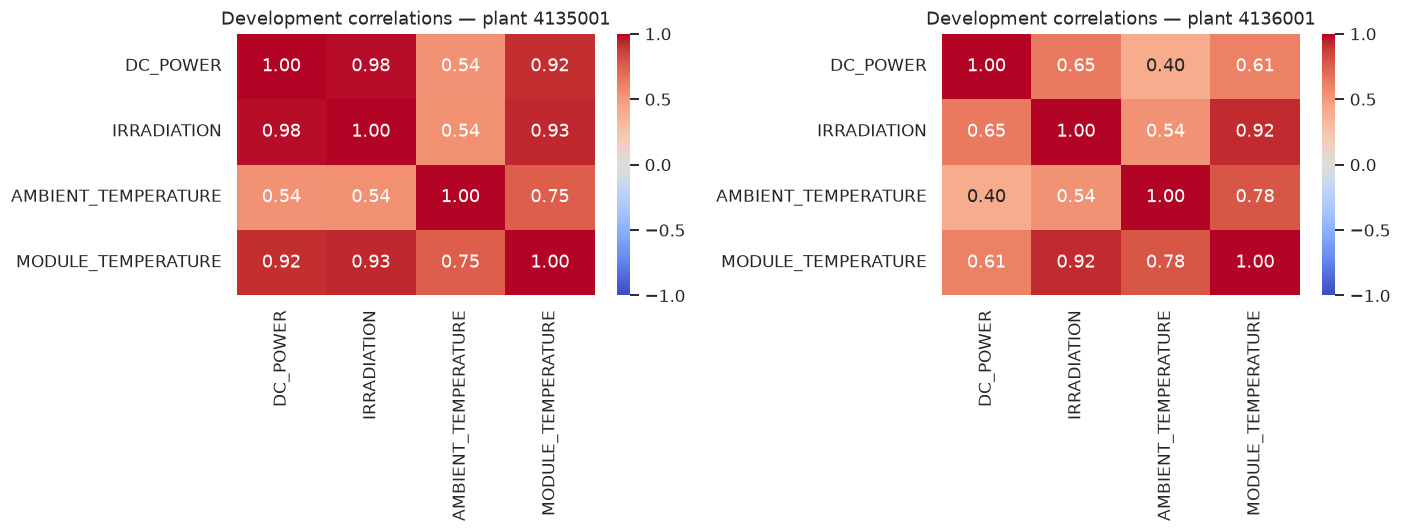

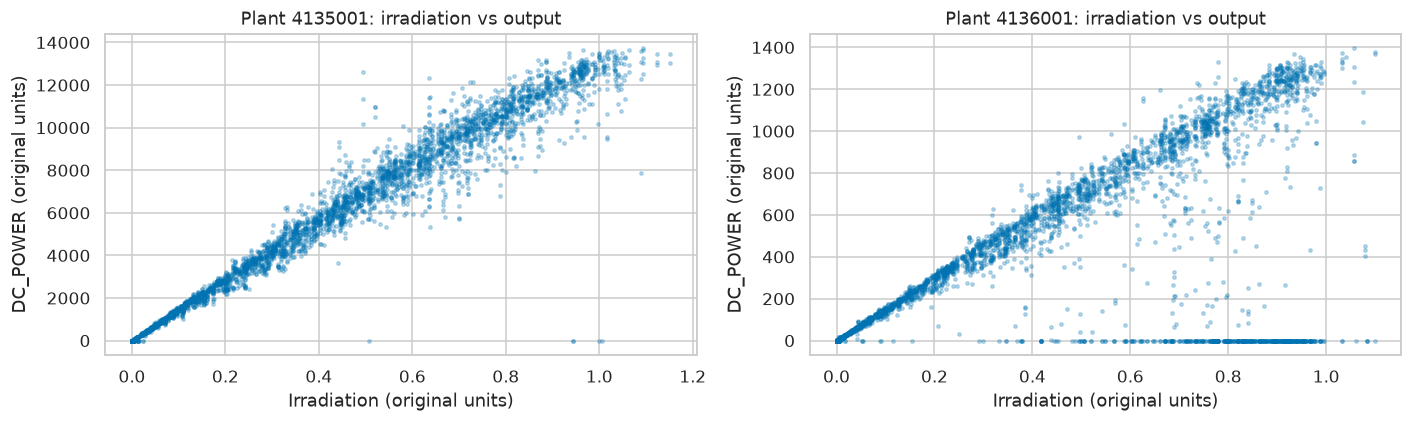

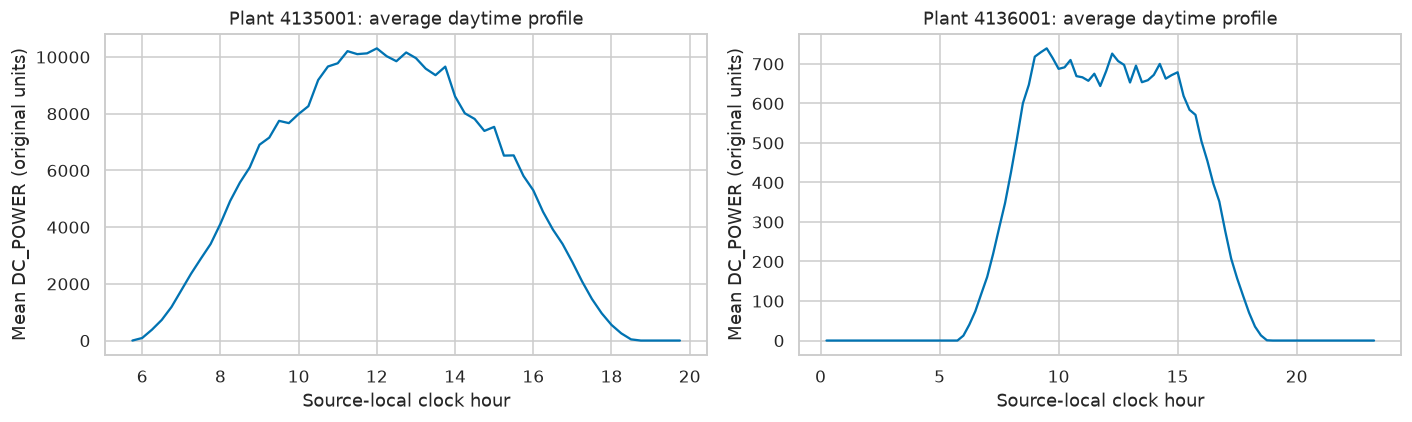

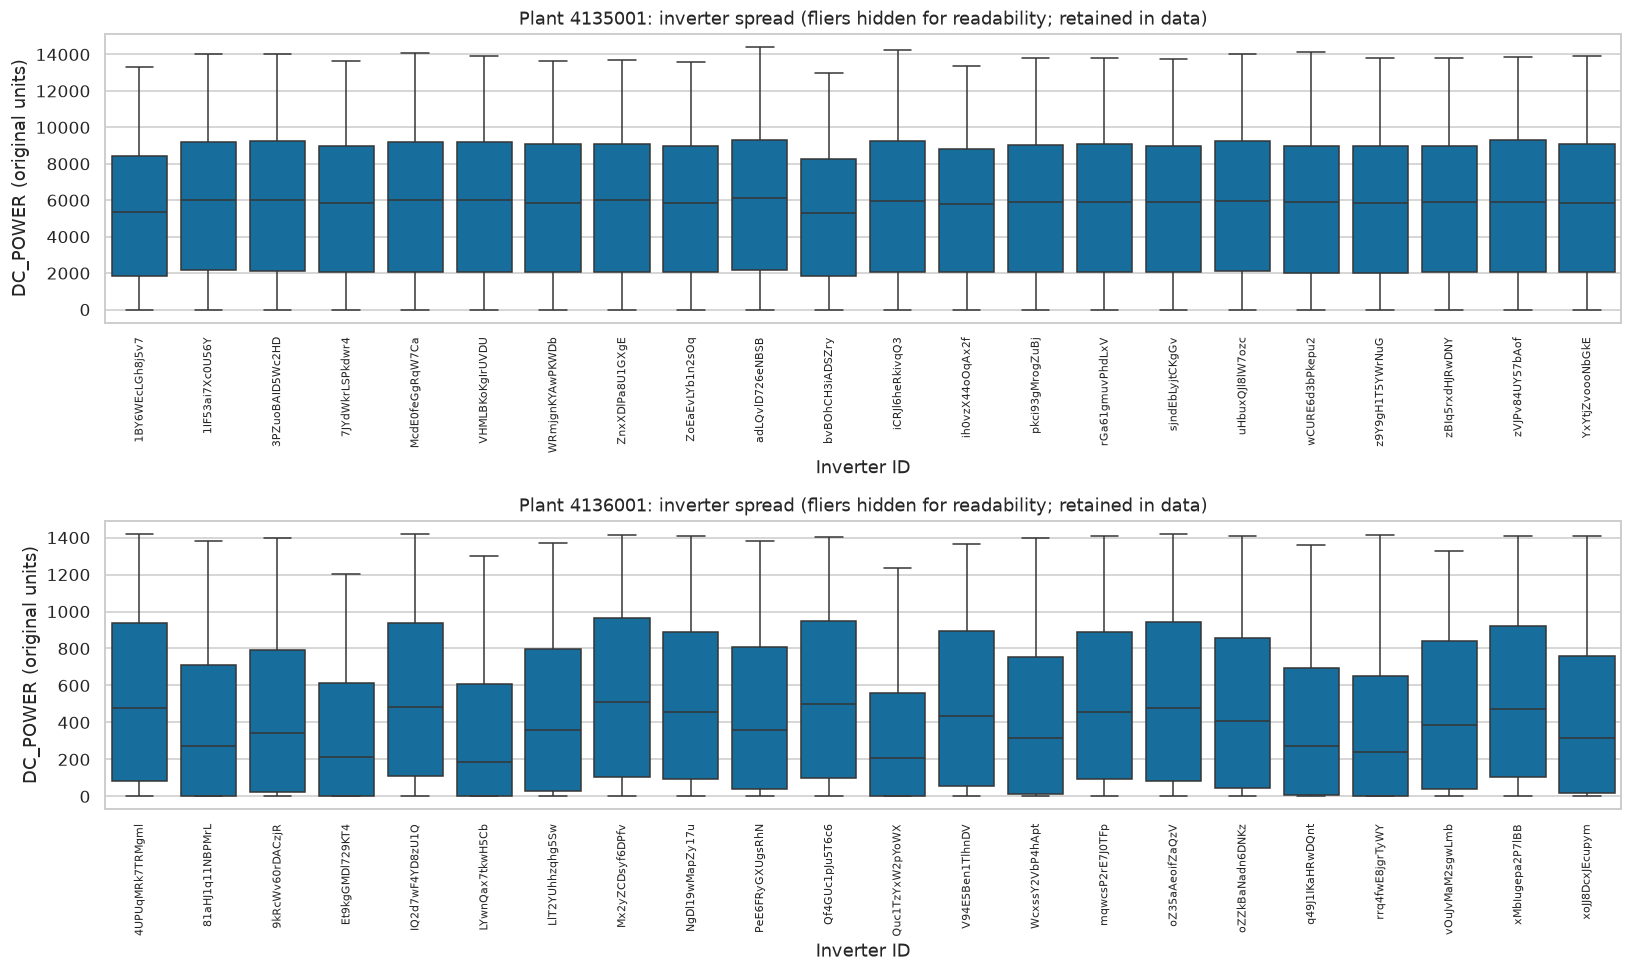

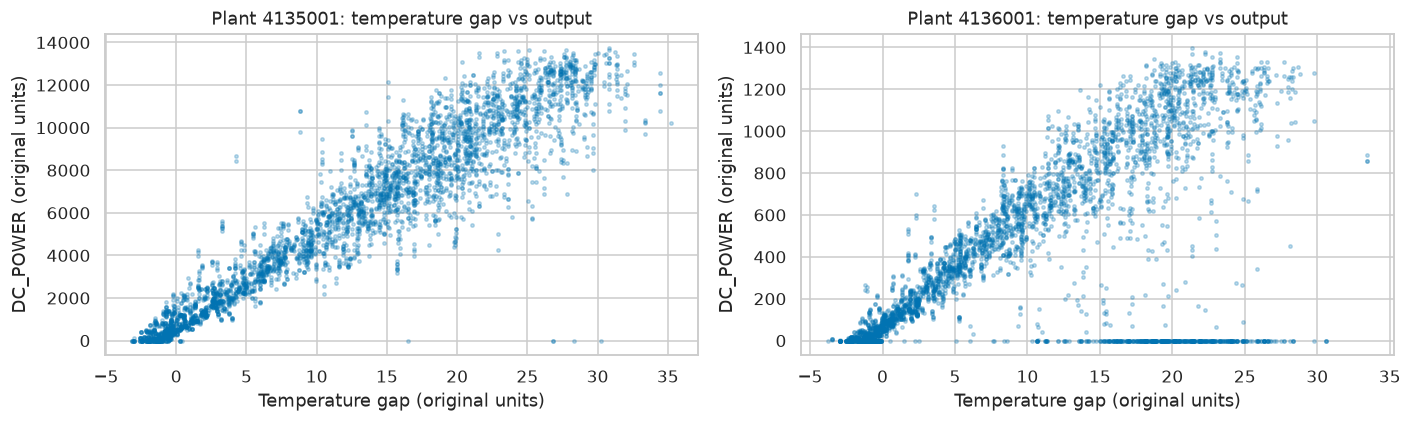

,plant,irradiation_DC_corr
0,4135001,0.9804
1,4136001,0.6471


**Interpretasi analisis eksploratif:** Plant 4135001: korelasi Pearson iradiasi/daya r=0.980; Plant 4136001: korelasi Pearson iradiasi/daya r=0.647. Hasil ini mendukung penggunaan iradiasi, tetapi tidak membuktikan sebab-akibat. Rata-rata daya mencapai puncak pada 12.00 jam waktu lokal sumber (Plant 4135001); 9.50 jam waktu lokal sumber (Plant 4136001). Pengodean waktu mempertahankan informasi menit. Selisih temperatur dinilai sebagai transformasi prediktif; korelasi cuaca dan waktu tidak memungkinkan klaim kausal tentang panas berlebih.

In [6]:
show_table(dev.groupby('PLANT_ID')[['DC_POWER'] + sensor_cols].describe().stack(level=0).reset_index(),
           'development_descriptive_statistics')
fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for row, (plant, part) in enumerate(dev.groupby('PLANT_ID')):
    for col, feature in enumerate(['DC_POWER'] + sensor_cols):
        sns.histplot(part[feature], bins=40, ax=axes[row, col])
        axes[row, col].set(title=f'Plant {plant}: {feature}', xlabel='Original dataset units', ylabel='Rows')
save_plot('eda_distributions')
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
correlations = []
for ax, (plant, part) in zip(axes, dev.groupby('PLANT_ID')):
    corr = part[['DC_POWER'] + sensor_cols].corr()
    sns.heatmap(corr, annot=True, fmt='.2f', vmin=-1, vmax=1, cmap='coolwarm', ax=ax)
    ax.set_title(f'Development correlations — plant {plant}')
    correlations.append({'plant': plant, 'irradiation_DC_corr': corr.loc['DC_POWER', 'IRRADIATION']})
save_plot('eda_correlations')
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (plant, part) in zip(axes, dev.groupby('PLANT_ID')):
    sample = part.sample(min(4000, len(part)), random_state=SEED)
    ax.scatter(sample.IRRADIATION, sample.DC_POWER, s=5, alpha=.25)
    ax.set(title=f'Plant {plant}: irradiation vs output', xlabel='Irradiation (original units)',
           ylabel='DC_POWER (original units)')
save_plot('eda_irradiation_power')
dev['CLOCK_HOUR'] = dev.DATE_TIME.dt.hour + dev.DATE_TIME.dt.minute / 60
hourly = dev.groupby(['PLANT_ID', 'CLOCK_HOUR']).DC_POWER.mean().reset_index()
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (plant, part) in zip(axes, hourly.groupby('PLANT_ID')):
    ax.plot(part.CLOCK_HOUR, part.DC_POWER)
    ax.set(title=f'Plant {plant}: average daytime profile', xlabel='Source-local clock hour',
           ylabel='Mean DC_POWER (original units)')
save_plot('eda_hourly_profile')
fig, axes = plt.subplots(2, 1, figsize=(15, 9))
for ax, (plant, part) in zip(axes, dev.groupby('PLANT_ID')):
    sns.boxplot(data=part, x='INVERTER_ID', y='DC_POWER', ax=ax, showfliers=False)
    ax.tick_params(axis='x', rotation=90, labelsize=7)
    ax.set(title=f'Plant {plant}: inverter spread (fliers hidden for readability; retained in data)',
           xlabel='Inverter ID', ylabel='DC_POWER (original units)')
save_plot('eda_inverter_spread')
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (plant, part) in zip(axes, dev.groupby('PLANT_ID')):
    sample = part.sample(min(4000, len(part)), random_state=SEED)
    ax.scatter(sample.MODULE_TEMPERATURE - sample.AMBIENT_TEMPERATURE,
               sample.DC_POWER, s=5, alpha=.25)
    ax.set(title=f'Plant {plant}: temperature gap vs output', xlabel='Temperature gap (original units)',
           ylabel='DC_POWER (original units)')
save_plot('eda_temperature_gap')
show_table(pd.DataFrame(correlations), 'eda_irradiation_correlations')
peaks = hourly.loc[hourly.groupby('PLANT_ID').DC_POWER.idxmax()]
note('**Interpretasi analisis eksploratif:** ' + '; '.join(f'Plant {r.plant}: korelasi Pearson iradiasi/daya r='
    f'{r.irradiation_DC_corr:.3f}' for r in pd.DataFrame(correlations).itertuples()) +
    '. Hasil ini mendukung penggunaan iradiasi, tetapi tidak membuktikan sebab-akibat. '
    'Rata-rata daya mencapai puncak pada ' + '; '.join(f'{r.CLOCK_HOUR:.2f} jam waktu lokal sumber (Plant {r.PLANT_ID})'
    for r in peaks.itertuples()) + '. Pengodean waktu mempertahankan informasi menit. Selisih temperatur dinilai '
    'sebagai transformasi prediktif; korelasi cuaca dan waktu tidak memungkinkan klaim kausal tentang panas berlebih.')

## 6. Rekayasa fitur

Fitur ditetapkan sebelum perbandingan: tiga sensor, sinus/kosinus waktu dengan pecahan
jam, selisih temperatur, iradiasi × temperatur modul, iradiasi kuadrat, serta identitas
pembangkit/inverter dengan pengodean one-hot. Interaksi dan suku polinomial memungkinkan
model linear mewakili sebagian hubungan nonlinear; model pohon dapat menangkap interaksi
lebih lanjut. Manfaat tambahan tiap fitur tidak diklaim tanpa studi penghilangan fitur.
DAY_OF_WEEK tidak digunakan karena pengamatan selama empat minggu belum cukup mendukung
adanya siklus operasional mingguan.

Imputasi median untuk fitur numerik dan nilai paling sering untuk kategori dipelajari
hanya dari bagian pelatihan setiap lipatan validasi. Penskalaan fitur numerik untuk
Linear Regression/Ridge juga berada dalam pipeline. Matriks one-hot padat mendukung
semua estimator, termasuk pencarian model linear dengan batas koefisien positif.
ID yang tidak dikenal dikodekan seluruhnya nol; ini menangani masukan perangkat lunak,
bukan membuktikan kemampuan pada lokasi baru. Target tidak diskalakan dan ID tidak
diberi kode label berurutan.

In [7]:
def engineer(frame):
    out = frame.copy()
    clock = out.DATE_TIME.dt.hour + out.DATE_TIME.dt.minute / 60
    out['HOUR_SIN'] = np.sin(2 * np.pi * clock / 24)
    out['HOUR_COS'] = np.cos(2 * np.pi * clock / 24)
    out['TEMP_GAP'] = out.MODULE_TEMPERATURE - out.AMBIENT_TEMPERATURE
    out['IRR_TEMP_INTERACTION'] = out.IRRADIATION * out.MODULE_TEMPERATURE
    out['IRR_SQUARED'] = out.IRRADIATION ** 2
    return out

dev, test = engineer(dev), engineer(test)
NUMERIC = sensor_cols + ['HOUR_SIN', 'HOUR_COS', 'TEMP_GAP', 'IRR_TEMP_INTERACTION', 'IRR_SQUARED']
CATEGORICAL = ['PLANT_ID', 'INVERTER_ID']
FEATURES = NUMERIC + CATEGORICAL
assert not set(FEATURES) & {'DC_POWER', 'AC_POWER', 'DAILY_YIELD', 'TOTAL_YIELD', 'SENSOR_ID'}
X_dev, y_dev = dev[FEATURES], dev.DC_POWER

def make_pipeline(estimator):
    numeric_steps = [('impute', SimpleImputer(strategy='median'))]
    if isinstance(estimator, (LinearRegression, Ridge)):
        numeric_steps.append(('scale', StandardScaler()))
    prep = ColumnTransformer([
        ('numeric', Pipeline(numeric_steps), NUMERIC),
        ('category', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), CATEGORICAL)
    ], sparse_threshold=0)
    return Pipeline([('prep', prep), ('model', estimator)])

display(pd.DataFrame({'feature': FEATURES, 'type': ['numeric'] * len(NUMERIC) + ['categorical'] * 2}))

,feature,type
0,IRRADIATION,numeric
1,AMBIENT_TEMPERATURE,numeric
2,MODULE_TEMPERATURE,numeric
3,HOUR_SIN,numeric
4,HOUR_COS,numeric
5,TEMP_GAP,numeric
6,IRR_TEMP_INTERACTION,numeric
7,IRR_SQUARED,numeric
8,PLANT_ID,categorical
9,INVERTER_ID,categorical


## 7. Model acuan dan validasi kronologis

Sebanyak 20% tanggal unik terakhir menjadi data uji yang dikunci, dengan pembulatan
ke tanggal utuh; tanggal sebelumnya menjadi data pengembangan. Lima lipatan validasi
silang dengan jendela pelatihan yang meluas membagi **tanggal**, bukan baris panel.
Semua inverter/pembangkit pada tanggal yang sama berada dalam bagian yang sama.
Jeda=0 sesuai untuk estimasi pada waktu yang sama, tanpa fitur tertunda atau label
masa depan yang tumpang tindih. Riwayat pelatihan bertambah pada lipatan berikutnya.

Model acuan rata-rata gabungan hanya mempelajari rata-rata target pelatihan. Pembanding
tambahan mempelajari rata-rata **per pembangkit**, sehingga perbedaan skala tidak
sepenuhnya menguntungkan model terlatih. Rata-rata ini dihitung ulang hanya dari bagian
pelatihan setiap lipatan; kategori baru memakai rata-rata gabungan pelatihan sebagai
cadangan. Pembanding tambahan memakai lipatan dan baris identik, tetapi hanya memerlukan
ID pembangkit; fitur cuaca tidak digunakan oleh model konstan ini.

**Metrik utama:**
rata-rata MAE tiap lipatan; **metrik sekunder:** RMSE, dengan R² sebagai pendukung.
MAPE tidak digunakan karena terdapat nilai nol atau mendekati nol. Perbandingan yang
adil menggunakan lipatan, baris, dan fitur identik untuk semua kandidat. Variasi antar
lipatan menggambarkan ketidakpastian deskriptif, bukan interval kepercayaan dengan
asumsi pengamatan saling independen dan berdistribusi identik.

**Status evaluasi tambahan:** pembanding per pembangkit ditambahkan setelah data uji
pernah diperiksa. Hasilnya merupakan analisis pelengkap, bukan evaluasi independen baru
atau dasar untuk memilih ulang model/fitur/ambang. Evaluasi sebelumnya direproduksi
dengan protokol yang sama; validasi baru diperlukan jika model dikembangkan lebih lanjut.

Semua simpangan baku antarlipatan pada tabel perbandingan memakai **ddof=1**. Simpangan
baku ini merangkum lima hasil kronologis, bukan galat baku atau interval kepercayaan.
Jendela pelatihan bertumpang tindih dan data berautokorelasi, sehingga simpangan baku
tidak dapat dipakai langsung sebagai uji signifikansi atau dibagi akar jumlah baris.

In [8]:
class PlantMeanRegressor(RegressorMixin, BaseEstimator):
    # No fitted preprocessing: only target means from the training partition.
    def fit(self, X, y):
        frame = pd.DataFrame({'plant': X['PLANT_ID'].to_numpy(), 'target': np.asarray(y)})
        self.means_ = frame.groupby('plant').target.mean()
        self.fallback_ = float(frame.target.mean())
        self.n_features_in_ = X.shape[1]
        return self

    def predict(self, X):
        return X['PLANT_ID'].map(self.means_).fillna(self.fallback_).to_numpy(dtype=float)

cv_splits, fold_rows = [], []
ordered_dates = np.sort(dev.DATE.unique())
for fold, (tr_d, va_d) in enumerate(TimeSeriesSplit(n_splits=5).split(ordered_dates), 1):
    tr = np.flatnonzero(dev.DATE.isin(ordered_dates[tr_d]).to_numpy())
    va = np.flatnonzero(dev.DATE.isin(ordered_dates[va_d]).to_numpy())
    assert dev.iloc[tr].DATE_TIME.max() < dev.iloc[va].DATE_TIME.min()
    assert set(dev.iloc[tr].DATE).isdisjoint(dev.iloc[va].DATE)
    assert set(dev.iloc[va].INVERTER_ID) <= set(dev.iloc[tr].INVERTER_ID)
    cv_splits.append((tr, va))
    fold_rows.append({'fold': fold, 'train_start': dev.iloc[tr].DATE.min(),
        'train_end': dev.iloc[tr].DATE.max(), 'validation_start': dev.iloc[va].DATE.min(),
        'validation_end': dev.iloc[va].DATE.max(), 'train_days': dev.iloc[tr].DATE.nunique(),
        'validation_days': dev.iloc[va].DATE.nunique(), 'train_rows': len(tr), 'validation_rows': len(va),
        'train_plants': dev.iloc[tr].PLANT_ID.nunique(), 'validation_plants': dev.iloc[va].PLANT_ID.nunique(),
        'train_inverters': dev.iloc[tr].INVERTER_ID.nunique(),
        'validation_inverters': dev.iloc[va].INVERTER_ID.nunique()})
show_table(pd.DataFrame(fold_rows), 'cv_folds')

def evaluate_cv(name, pipe):
    rows, plant_rows, predictions = [], [], []
    for fold, (tr, va) in enumerate(cv_splits, 1):
        model = clone(pipe)
        start = time.perf_counter()
        model.fit(X_dev.iloc[tr], y_dev.iloc[tr])
        fit_s = time.perf_counter() - start
        pred = model.predict(X_dev.iloc[va])
        rows.append({'model': name, 'fold': fold, **metrics(y_dev.iloc[va], pred), 'fit_seconds': fit_s})
        frame = dev.iloc[va][['PLANT_ID', 'INVERTER_ID', 'DATE_TIME', 'DATE', 'IRRADIATION']].copy()
        frame['actual'], frame['predicted'] = y_dev.iloc[va].to_numpy(), pred
        frame['fold'] = fold
        predictions.append(frame)
        for plant, idx in frame.groupby('PLANT_ID').indices.items():
            plant_rows.append({'model': name, 'fold': fold, 'plant': plant,
                **metrics(frame.iloc[idx].actual, frame.iloc[idx].predicted)})
    return pd.DataFrame(rows), pd.DataFrame(plant_rows), pd.concat(predictions, ignore_index=True)

baseline_pipe = make_pipeline(DummyRegressor(strategy='mean'))
base_folds, base_plant, base_oof = evaluate_cv('Mean baseline', baseline_pipe)
show_table(base_folds, 'baseline_cv_folds')
plant_baseline = PlantMeanRegressor()
plant_base_folds, plant_base_scores, plant_base_oof = evaluate_cv('Plant mean baseline', plant_baseline)
show_table(plant_base_folds, 'plant_mean_baseline_cv_folds')
show_table(plant_base_scores, 'plant_mean_baseline_cv_by_plant')
plant_calibration = []
for fold, (tr, va) in enumerate(cv_splits, 1):
    for plant, part in dev.iloc[tr].groupby('PLANT_ID'):
        plant_calibration.append({'fold': fold, 'plant': plant, 'training_rows': len(part),
            'training_end': part.DATE_TIME.max(), 'training_mean': part.DC_POWER.mean()})
show_table(pd.DataFrame(plant_calibration), 'plant_mean_baseline_training_audit')
show_table(pd.concat([base_folds, plant_base_folds]).groupby('model', as_index=False).agg(
    CV_MAE=('MAE', 'mean'), CV_MAE_SD=('MAE', 'std'), CV_RMSE=('RMSE', 'mean'),
    CV_R2=('R2', 'mean')), 'baseline_cv_comparison')
note(f'MAE validasi silang model acuan rata-rata pada data pengembangan = **{base_folds.MAE.mean():,.3f}** '
     f'(simpangan baku antar lipatan {base_folds.MAE.std():,.3f}), dalam satuan target asli. '
     f'MAE pembanding rata-rata per pembangkit = **{plant_base_folds.MAE.mean():,.3f}** '
     f'(simpangan baku antar lipatan {plant_base_folds.MAE.std():,.3f}). '
     'Keduanya menjadi tolok ukur kinerja, bukan aturan inspeksi. Pembanding tambahan tidak masuk seleksi ulang.')

,fold,train_start,train_end,validation_start,validation_end,train_days,validation_days,train_rows,validation_rows,train_plants,validation_plants,train_inverters,validation_inverters
0,1,2020-05-15,2020-05-21,2020-05-22,2020-05-25,7,4,15475,8346,2,2,44,40
1,2,2020-05-15,2020-05-25,2020-05-26,2020-05-29,11,4,23821,8453,2,2,44,44
2,3,2020-05-15,2020-05-29,2020-05-30,2020-06-02,15,4,32274,9392,2,2,44,44
3,4,2020-05-15,2020-06-02,2020-06-03,2020-06-06,19,4,41666,9274,2,2,44,44
4,5,2020-05-15,2020-06-06,2020-06-07,2020-06-10,23,4,50940,9570,2,2,44,44


,model,fold,n,MAE,RMSE,R2,bias_actual_minus_pred,fit_seconds
0,Mean baseline,1,8346,"3,552.4335","4,397.6694",-0.0415,878.1615,0.0537
1,Mean baseline,2,8453,"3,429.8268","4,059.6164",-0.0082,366.9394,0.0344
2,Mean baseline,3,9392,"3,128.3802","3,598.4700",-0.0209,-515.1830,0.0493
3,Mean baseline,4,9274,"3,294.1268","3,833.5557",-0.0003,-61.8533,0.0533
4,Mean baseline,5,9570,"3,341.6213","3,932.1086",-0.0003,-62.2559,0.0620


,model,fold,n,MAE,RMSE,R2,bias_actual_minus_pred,fit_seconds
0,Plant mean baseline,1,8346,"2,289.7134","3,234.6805",0.4365,556.8368,0.0033
1,Plant mean baseline,2,8453,"2,034.6218","2,936.0918",0.4726,164.2200,0.0057
2,Plant mean baseline,3,9392,"1,800.3780","2,699.1955",0.4256,-384.0303,0.0055
3,Plant mean baseline,4,9274,"1,795.9874","2,708.9541",0.5005,8.8739,0.0059
4,Plant mean baseline,5,9570,"1,896.7661","2,820.3918",0.4854,34.5582,0.0069


,model,fold,plant,n,MAE,RMSE,R2,bias_actual_minus_pred
0,Plant mean baseline,1,4135001,4530,"3,868.2805","4,369.3205",-0.0494,947.7369
1,Plant mean baseline,1,4136001,3816,415.7854,470.1411,-0.0405,92.7965
2,Plant mean baseline,2,4135001,4557,"3,437.2083","3,978.2095",-0.0046,270.2332
3,Plant mean baseline,2,4136001,3896,394.0708,438.8877,-0.0085,40.2205
4,Plant mean baseline,3,4135001,4574,"3,324.4035","3,845.7448",-0.0370,-726.0939
5,Plant mean baseline,3,4136001,4818,353.5345,401.9870,-0.0222,-59.2900
6,Plant mean baseline,4,4135001,4566,"3,313.5959","3,840.9537",-0.0005,82.4178
7,Plant mean baseline,4,4136001,4708,324.1520,384.1506,-0.0271,-62.4518
8,Plant mean baseline,5,4135001,4642,"3,524.8374","4,027.5925",-0.0010,125.3941
9,Plant mean baseline,5,4136001,4928,363.1811,409.2595,-0.0158,-51.0059


,fold,plant,training_rows,training_end,training_mean
0,1,4135001,7411,2020-05-21 18:30:00,"5,478.3603"
1,1,4136001,8064,2020-05-21 18:45:00,447.7211
2,2,4135001,11941,2020-05-25 18:45:00,"5,837.8988"
3,2,4136001,11880,2020-05-25 18:45:00,477.5285
4,3,4135001,16498,2020-05-29 18:30:00,"5,912.5413"
5,3,4136001,15776,2020-05-29 18:45:00,487.4613
6,4,4135001,21072,2020-06-02 18:45:00,"5,754.9315"
7,4,4136001,20594,2020-06-02 18:45:00,473.5903
8,5,4135001,25638,2020-06-06 18:30:00,"5,769.6097"
9,5,4136001,25302,2020-06-06 18:45:00,461.9697


,model,CV_MAE,CV_MAE_SD,CV_RMSE,CV_R2
0,Mean baseline,"3,349.2777",157.8420,"3,964.2840",-0.0142
1,Plant mean baseline,"1,963.4933",206.5164,"2,879.8627",0.4641


MAE validasi silang model acuan rata-rata pada data pengembangan = **3,349.278** (simpangan baku antar lipatan 157.842), dalam satuan target asli. MAE pembanding rata-rata per pembangkit = **1,963.493** (simpangan baku antar lipatan 206.516). Keduanya menjadi tolok ukur kinerja, bukan aturan inspeksi. Pembanding tambahan tidak masuk seleksi ulang.

## 8. Kandidat model

Linear Regression menjadi pembanding aditif yang mudah diinterpretasikan. Ridge
memberi regularisasi pada fitur hasil rekayasa yang berkorelasi. Random Forest menangkap
interaksi nonlinear melalui penggabungan pohon hasil pengambilan sampel ulang.
Gradient Boosting Regressor merupakan estimator sklearn, **bukan XGBoost**. Random Forest
menggunakan pengaturan awal 100 pohon, seed tetap, dan jumlah utas terbatas; Gradient
Boosting menggunakan parameter struktur awal dan seed tetap. Pengaturan awal lain ditampilkan.

Tidak ada prediksi data uji pada tahap ini. Dua kandidat terbaik selain model acuan
ditentukan berdasarkan MAE validasi silang. Urutan abjad menjadi pemecah seri hanya
jika nilainya persis sama. Waktu pelatihan awal digunakan untuk menetapkan anggaran
pencarian sebelum penyetelan parameter.

Evaluating Linear Regression...
  CV MAE 1559.473; fit total 0.6s
Evaluating Ridge...
  CV MAE 1559.917; fit total 0.3s
Evaluating Random Forest...
  CV MAE 294.844; fit total 18.4s
Evaluating Gradient Boosting...
  CV MAE 294.003; fit total 23.8s


,model,fold,n,MAE,RMSE,R2,bias_actual_minus_pred,fit_seconds
0,Mean baseline,1,8346,"3,552.4335","4,397.6694",-0.0415,878.1615,0.0537
1,Mean baseline,2,8453,"3,429.8268","4,059.6164",-0.0082,366.9394,0.0344
2,Mean baseline,3,9392,"3,128.3802","3,598.4700",-0.0209,-515.1830,0.0493
3,Mean baseline,4,9274,"3,294.1268","3,833.5557",-0.0003,-61.8533,0.0533
4,Mean baseline,5,9570,"3,341.6213","3,932.1086",-0.0003,-62.2559,0.0620
5,Linear Regression,1,8346,"1,717.0936","2,020.3939",0.7802,-5.8329,0.0618
6,Linear Regression,2,8453,"1,443.4814","1,742.3656",0.8143,-128.0405,0.0901
7,Linear Regression,3,9392,"1,565.5276","1,849.0507",0.7304,-13.6109,0.1222
8,Linear Regression,4,9274,"1,481.4829","1,787.4191",0.7825,-134.9428,0.1722
9,Linear Regression,5,9570,"1,589.7798","1,904.5617",0.7653,-56.8499,0.1949


,model,CV_MAE,CV_MAE_SD,CV_RMSE,CV_R2,total_fit_seconds
0,Gradient Boosting,294.0030,28.8655,572.0356,0.9777,23.7663
3,Random Forest,294.8444,35.6361,602.3319,0.9756,18.4056
1,Linear Regression,"1,559.4730",106.4612,"1,860.7582",0.7746,0.6411
4,Ridge,"1,559.9166",106.7307,"1,861.0094",0.7745,0.3295
2,Mean baseline,"3,349.2777",157.8420,"3,964.2840",-0.0142,0.2526


,model,plant,CV_MAE,CV_MAE_SD,CV_RMSE
0,Gradient Boosting,4135001,403.6347,37.0918,742.7683
1,Gradient Boosting,4136001,182.4301,37.5746,307.6148
2,Linear Regression,4135001,"1,643.9734",103.2030,"1,964.2904"
3,Linear Regression,4136001,"1,470.5034",130.5263,"1,742.3409"
4,Mean baseline,4135001,"4,000.8572",415.9811,"4,862.8627"
5,Mean baseline,4136001,"2,650.2942",197.9962,"2,683.3518"
6,Random Forest,4135001,417.7337,34.5978,780.7179
7,Random Forest,4136001,168.7903,42.2236,323.9821
8,Ridge,4135001,"1,644.4114",102.5958,"1,964.5960"
9,Ridge,4136001,"1,471.0708",131.4192,"1,742.7064"


{'Linear Regression': {'copy_X': True,
  'fit_intercept': True,
  'n_jobs': None,
  'positive': False,
  'tol': 1e-06},
 'Ridge': {'alpha': 1.0,
  'copy_X': True,
  'fit_intercept': True,
  'max_iter': None,
  'positive': False,
  'random_state': None,
  'solver': 'auto',
  'tol': 0.0001},
 'Random Forest': {'bootstrap': True,
  'ccp_alpha': 0.0,
  'criterion': 'squared_error',
  'max_depth': None,
  'max_features': 1.0,
  'max_leaf_nodes': None,
  'max_samples': None,
  'min_impurity_decrease': 0.0,
  'min_samples_leaf': 1,
  'min_samples_split': 2,
  'min_weight_fraction_leaf': 0.0,
  'monotonic_cst': None,
  'n_estimators': 100,
  'n_jobs': 4,
  'oob_score': False,
  'random_state': 42,
  'verbose': 0,
  'warm_start': False},
 'Gradient Boosting': {'alpha': 0.9,
  'ccp_alpha': 0.0,
  'criterion': 'deprecated',
  'init': None,
  'learning_rate': 0.1,
  'loss': 'squared_error',
  'max_depth': 3,
  'max_features': None,
  'max_leaf_nodes': None,
  'min_impurity_decrease': 0.0,
  'min_s

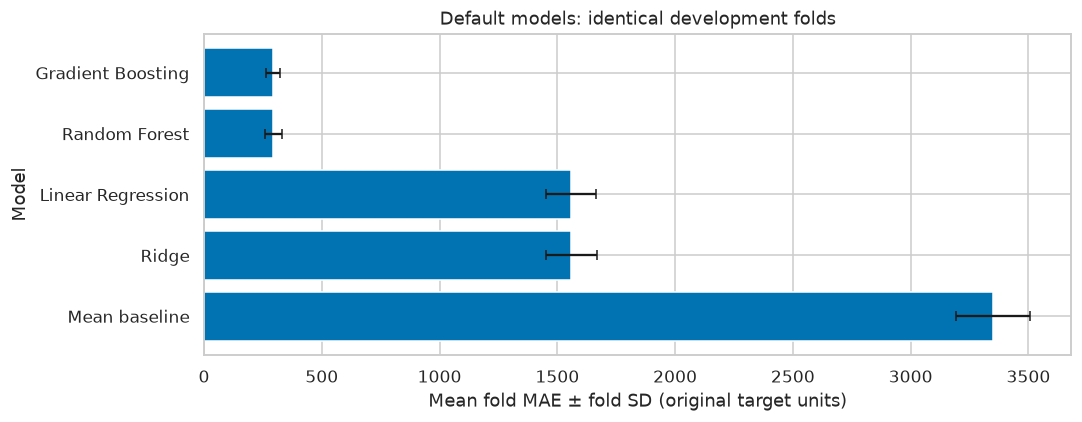

**Dipilih untuk penyetelan:** Gradient Boosting, Random Forest. Pemilihan hanya memakai validasi silang data pengembangan. Simpangan baku besar menunjukkan variasi antar jendela kronologis; nilainya bukan bukti estimasi rata-rata yang presisi dengan asumsi pengamatan independen.

In [9]:
models = {
    'Linear Regression': make_pipeline(LinearRegression()),
    'Ridge': make_pipeline(Ridge()),
    'Random Forest': make_pipeline(RandomForestRegressor(random_state=SEED, n_jobs=WORKERS)),
    'Gradient Boosting': make_pipeline(GradientBoostingRegressor(random_state=SEED))
}
all_folds, all_plants = [base_folds], [base_plant]
default_oof = {'Mean baseline': base_oof}
for name, pipe in models.items():
    print(f'Evaluating {name}...', flush=True)
    folds, plants, oof = evaluate_cv(name, pipe)
    all_folds.append(folds)
    all_plants.append(plants)
    default_oof[name] = oof
    print(f'  CV MAE {folds.MAE.mean():.3f}; fit total {folds.fit_seconds.sum():.1f}s', flush=True)
default_folds = pd.concat(all_folds, ignore_index=True)
default_plants = pd.concat(all_plants, ignore_index=True)
ranking = default_folds.groupby('model', as_index=False).agg(
    CV_MAE=('MAE', 'mean'), CV_MAE_SD=('MAE', 'std'), CV_RMSE=('RMSE', 'mean'),
    CV_R2=('R2', 'mean'), total_fit_seconds=('fit_seconds', 'sum')).sort_values(['CV_MAE', 'model'])
show_table(default_folds, 'default_cv_fold_scores')
show_table(ranking, 'default_cv_ranking')
show_table(default_plants.groupby(['model', 'plant'], as_index=False).agg(
    CV_MAE=('MAE', 'mean'), CV_MAE_SD=('MAE', 'std'), CV_RMSE=('RMSE', 'mean')),
    'default_cv_by_plant')
selected = ranking.loc[ranking.model.ne('Mean baseline'), 'model'].head(2).tolist()
assert len(selected) == 2
default_parameters = {n: p.named_steps['model'].get_params() for n, p in models.items()}
(OUT / 'default_parameters.json').write_text(json.dumps(default_parameters, indent=2, default=str))
display(default_parameters)
fig, ax = plt.subplots(figsize=(10, 4))
ax.barh(ranking.model, ranking.CV_MAE, xerr=ranking.CV_MAE_SD, capsize=3)
ax.invert_yaxis()
ax.set(title='Default models: identical development folds',
    xlabel='Mean fold MAE ± fold SD (original target units)', ylabel='Model')
save_plot('default_cv_comparison')
note(f'**Dipilih untuk penyetelan:** {", ".join(selected)}. Pemilihan hanya memakai validasi silang data pengembangan. '
     'Simpangan baku besar menunjukkan variasi antar jendela kronologis; nilainya bukan bukti estimasi rata-rata yang presisi dengan asumsi pengamatan independen.')

## 9. Penyetelan hiperparameter

Sedikitnya dua parameter relevan disetel pada masing-masing dari dua kandidat terpilih.
Pencarian menggunakan lima lipatan tanggal yang identik dan skor MAE negatif, yang
dikonversi kembali menjadi galat positif. Linear Regression: intersep dan batas
koefisien positif; batas ini berlaku pada fitur numerik yang diskalakan dan fitur
one-hot, sebagai kandidat empiris, bukan asumsi kausal fisik. Ridge: alpha dan intersep.
Random Forest: jumlah/kedalaman pohon, ukuran daun, dan pengambilan sebagian fitur.
Gradient Boosting: jumlah tahap, laju pembelajaran, kedalaman pohon, pengambilan sebagian
baris, dan ukuran daun.

Anggaran ditetapkan setelah pelatihan awal dan sebelum pencarian: paling banyak
**4 konfigurasi sampel** per model ansambel, sesuai batas maksimum 12 pada rencana,
agar waktu eksekusi seluruh data tetap wajar. Semua kombinasi digunakan jika ruang
pencarian berjumlah paling banyak 4. Pelatihan tidak mengambil sebagian baris;
pengambilan sampel hanya untuk grafik dan diagnosis permutasi. Ini pencarian sistematis
yang terbatas, bukan klaim solusi terbaik secara global. Pencarian memakai satu proses
pekerja dan jumlah utas estimator/BLAS yang dibatasi. Skor validasi silang dipakai ulang
untuk pemeringkatan dan pencarian sehingga hasil terpilih dapat terlalu optimistis;
data uji yang belum disentuh menjadi pemeriksaan akhir yang independen.

Tuning Gradient Boosting: 4 configs x 5 folds


{'model__n_estimators': [100, 200, 300],
 'model__learning_rate': [0.03, 0.05, 0.1],
 'model__max_depth': [2, 3, 5],
 'model__subsample': [0.8, 1.0],
 'model__min_samples_leaf': [1, 4]}

Best CV MAE 354.049; runtime 215.3s
Tuning Random Forest: 4 configs x 5 folds


{'model__n_estimators': [100, 200, 300],
 'model__max_depth': [10, 20, None],
 'model__min_samples_leaf': [1, 2, 4],
 'model__max_features': [1.0, 0.5, 'sqrt']}

Best CV MAE 290.620; runtime 66.5s


,model,configurations,folds,default_CV_MAE,tuned_CV_MAE,tuned_CV_MAE_SD,SD_ddof,tuned_CV_RMSE,tuned_CV_R2,MAE_improvement,improvement_pct,search_seconds,best_parameters
0,Gradient Boosting,4,5,294.0030,354.0493,27.9569,1,626.1735,0.9735,-60.0463,-20.4237,215.2895,"{""model__subsample"": 1.0, ""model__n_estimators..."
1,Random Forest,4,5,294.8444,290.6201,34.5917,1,591.7520,0.9764,4.2244,1.4327,66.4735,"{""model__n_estimators"": 100, ""model__min_sampl..."


,model,fold,default_MAE,tuned_MAE,MAE_reduction_default_minus_tuned
0,Gradient Boosting,1,313.8733,369.8342,-55.9610
1,Gradient Boosting,2,301.8300,354.2495,-52.4195
2,Gradient Boosting,3,247.6943,320.0571,-72.3628
3,Gradient Boosting,4,286.5891,335.1284,-48.5393
4,Gradient Boosting,5,320.0285,390.9773,-70.9488
5,Random Forest,1,336.6045,327.2758,9.3288
6,Random Forest,2,312.1772,308.7039,3.4733
7,Random Forest,3,245.6215,240.2488,5.3727
8,Random Forest,4,273.1199,271.5708,1.5490
9,Random Forest,5,306.6991,305.3010,1.3981


**Penjelasan statistik:** selisih berpasangan memakai lipatan identik; nilai positif berarti penyetelan menurunkan MAE pada lipatan tersebut. Simpangan baku tabel memakai ddof=1 untuk pengaturan awal dan hasil penyetelan. Kolom std_test_mae pada berkas mentah cv_results_ tetap mengikuti sklearn (ddof=0), sehingga tidak dibandingkan langsung dengan simpangan baku tabel. Lima lipatan yang bergantung tidak mendukung klaim signifikansi atau interval kepercayaan independen dari tabel ini.

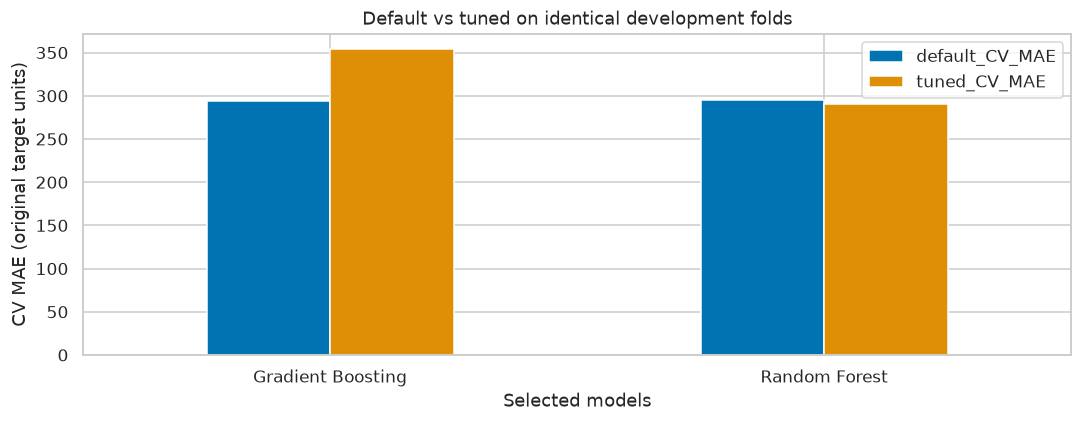

In [10]:
spaces = {
    'Linear Regression': {'model__fit_intercept': [True, False], 'model__positive': [False, True]},
    'Ridge': {'model__alpha': [0.01, 0.1, 1.0, 10.0, 100.0], 'model__fit_intercept': [True, False]},
    'Random Forest': {'model__n_estimators': [100, 200, 300], 'model__max_depth': [10, 20, None],
        'model__min_samples_leaf': [1, 2, 4], 'model__max_features': [1.0, 0.5, 'sqrt']},
    'Gradient Boosting': {'model__n_estimators': [100, 200, 300], 'model__learning_rate': [0.03, 0.05, 0.1],
        'model__max_depth': [2, 3, 5], 'model__subsample': [0.8, 1.0], 'model__min_samples_leaf': [1, 4]}
}
searches, tuning_rows = {}, []
for name in selected:
    assert len(spaces[name]) >= 2
    budget = min(4 if name != 'Ridge' else 10, len(ParameterGrid(spaces[name])))
    print(f'Tuning {name}: {budget} configs x {len(cv_splits)} folds', flush=True)
    display(spaces[name])
    start = time.perf_counter()
    search = RandomizedSearchCV(models[name], spaces[name], n_iter=budget, cv=cv_splits,
        scoring={'mae': 'neg_mean_absolute_error', 'rmse': 'neg_root_mean_squared_error', 'r2': 'r2'},
        refit='mae', random_state=SEED, n_jobs=1, error_score='raise', return_train_score=False)
    search.fit(X_dev, y_dev)
    elapsed = time.perf_counter() - start
    searches[name] = search
    results = pd.DataFrame(search.cv_results_)
    results.to_csv(OUT / (name.lower().replace(' ', '_') + '_search_results.csv'), index=False)
    idx = search.best_index_
    base = ranking.set_index('model').loc[name]
    tuned_mae = -results.loc[idx, 'mean_test_mae']
    best_fold_mae = np.array([-results.loc[idx, f'split{k}_test_mae'] for k in range(len(cv_splits))])
    tuning_rows.append({'model': name, 'configurations': budget, 'folds': len(cv_splits),
        'default_CV_MAE': base.CV_MAE, 'tuned_CV_MAE': tuned_mae,
        'tuned_CV_MAE_SD': best_fold_mae.std(ddof=1),
        'SD_ddof': 1,
        'tuned_CV_RMSE': -results.loc[idx, 'mean_test_rmse'],
        'tuned_CV_R2': results.loc[idx, 'mean_test_r2'],
        'MAE_improvement': base.CV_MAE - tuned_mae,
        'improvement_pct': 100 * (base.CV_MAE - tuned_mae) / base.CV_MAE if base.CV_MAE else np.nan,
        'search_seconds': elapsed, 'best_parameters': json.dumps(search.best_params_)})
    print(f'Best CV MAE {tuned_mae:.3f}; runtime {elapsed:.1f}s', flush=True)
tuning = pd.DataFrame(tuning_rows)
show_table(tuning, 'default_vs_tuned')
paired_rows = []
for name in selected:
    search = searches[name]
    result = pd.DataFrame(search.cv_results_).loc[search.best_index_]
    for k, base in enumerate(default_folds.loc[default_folds.model.eq(name)].sort_values('fold').itertuples()):
        paired_rows.append({'model': name, 'fold': k + 1, 'default_MAE': base.MAE,
            'tuned_MAE': -result[f'split{k}_test_mae'],
            'MAE_reduction_default_minus_tuned': base.MAE + result[f'split{k}_test_mae']})
paired_tuning = pd.DataFrame(paired_rows)
show_table(paired_tuning, 'paired_default_vs_tuned_folds')
note('**Penjelasan statistik:** selisih berpasangan memakai lipatan identik; nilai positif berarti '
     'penyetelan menurunkan MAE pada lipatan tersebut. Simpangan baku tabel memakai ddof=1 '
     'untuk pengaturan awal dan hasil penyetelan. Kolom std_test_mae pada berkas mentah '
     'cv_results_ tetap mengikuti sklearn (ddof=0), sehingga tidak dibandingkan langsung '
     'dengan simpangan baku tabel. Lima lipatan yang bergantung tidak mendukung klaim '
     'signifikansi atau interval kepercayaan independen dari tabel ini.')
fig, ax = plt.subplots(figsize=(10, 4))
tuning.set_index('model')[['default_CV_MAE', 'tuned_CV_MAE']].plot.bar(ax=ax)
ax.set(title='Default vs tuned on identical development folds', xlabel='Selected models',
       ylabel='CV MAE (original target units)')
ax.tick_params(axis='x', rotation=0)
save_plot('default_vs_tuned')

## 10. Evaluasi dan pemilihan model akhir

Pemilihan akhir mempertimbangkan seluruh kandidat dengan pengaturan awal, kedua
kandidat hasil penyetelan, dan model acuan, berdasarkan MAE validasi silang data
pengembangan terendah. Tidak ada keharusan memilih model ansambel atau hasil penyetelan.
Jika nilainya persis sama, pengaturan awal didahulukan, kemudian urutan nama. Seluruh
fitur, prapemrosesan, parameter, metrik, dan aturan peringatan dikunci sebelum prediksi data uji.

Aturan peringatan dikalibrasi menggunakan prediksi model terpilih pada data
**pengembangan** di luar bagian pelatihan masing-masing lipatan (OOF). Untuk setiap
pembangkit, ambang ditentukan dari persentil ke-95 selisih positif prediksi−aktual,
dengan daya estimasi minimum pada persentil ke-25 prediksi OOF dan **3 interval 15 menit
berturut-turut**. Hanya selisih positif di atas ambang yang dihitung. Kuantil dan syarat
keberlanjutan merupakan pilihan prototipe yang ditentukan sebelumnya, bukan ambang
optimal untuk kerusakan. Waktu pengamatan yang terputus mengulang perhitungan urutan.
Jendela pelatihan pertama tidak memiliki prediksi OOF sehingga tidak digunakan dalam kalibrasi.

Hasil test di bawah mereproduksi evaluasi awal untuk model yang tetap sama. Pembanding
per pembangkit ditambahkan secara deskriptif setelah test pernah dilihat. Tidak ada
perubahan ruang pencarian, objective, fitur, model terpilih, atau kebijakan peringatan.

In [11]:
pool = []
for row in ranking.itertuples():
    pipe = baseline_pipe if row.model == 'Mean baseline' else models[row.model]
    pool.append({'candidate': row.model + ' [default]', 'model': row.model, 'variant': 'default',
                 'CV_MAE': row.CV_MAE, 'pipeline': pipe})
for row in tuning.itertuples():
    pool.append({'candidate': row.model + ' [tuned]', 'model': row.model, 'variant': 'tuned',
        'CV_MAE': row.tuned_CV_MAE, 'pipeline': searches[row.model].best_estimator_})
pool.sort(key=lambda x: (x['CV_MAE'], x['variant'] != 'default', x['candidate']))
chosen = pool[0]
show_table(pd.DataFrame([{k: v for k, v in x.items() if k != 'pipeline'} for x in pool]),
           'final_development_selection')
chosen_pipe = clone(chosen['pipeline'])
if chosen['variant'] == 'default':
    selected_oof = default_oof[chosen['model']].copy()
else:
    _, _, selected_oof = evaluate_cv(chosen['candidate'], chosen_pipe)
selected_oof['gap'] = selected_oof.predicted - selected_oof.actual
threshold_rows = []
for plant, part in selected_oof.groupby('PLANT_ID'):
    positives = part.loc[part.gap > 0, 'gap']
    threshold_rows.append({'PLANT_ID': plant,
        'gap_threshold': float(positives.quantile(.95)) if len(positives) else float('inf'),
        'min_expected': max(0.0, float(part.predicted.quantile(.25))),
        'persistence_intervals': 3, 'oof_rows': len(part), 'positive_gap_rows': len(positives)})
thresholds = pd.DataFrame(threshold_rows)
show_table(thresholds, 'development_alert_thresholds')
lock = {'selected': chosen['candidate'], 'selected_CV_MAE': float(chosen['CV_MAE']),
    'metric': 'mean_fold_MAE_original_scale', 'features': FEATURES, 'horizon': 0,
    'seed': SEED, 'parameters': chosen_pipe.named_steps['model'].get_params(),
    'thresholds': threshold_rows, 'locked_before_test_prediction': True,
    'utc_lock_time': datetime.now(timezone.utc).isoformat()}
lock['evaluation_status'] = 'reproduction_after_test_exposure'
lock['supplemental_baseline_used_for_selection'] = False
initial_lock_path = OUT / 'initial_selection_lock.json'
if initial_lock_path.exists():
    original_lock = json.loads(initial_lock_path.read_text())
    assert chosen['candidate'] == original_lock['selected'], 'Original selection must remain unchanged'
    assert FEATURES == original_lock['features']
    assert {k: v for k, v in lock['parameters'].items() if k != 'n_jobs'} == {
        k: v for k, v in original_lock['parameters'].items() if k != 'n_jobs'}
    for original, current in zip(original_lock['thresholds'], threshold_rows):
        assert original['PLANT_ID'] == current['PLANT_ID']
        assert np.isclose(original['gap_threshold'], current['gap_threshold'])
        assert np.isclose(original['min_expected'], current['min_expected'])
    lock['original_lock_time'] = original_lock['utc_lock_time']
(OUT / 'selection_lock.json').write_text(json.dumps(lock, indent=2, default=str))
note(f'**Pilihan yang dikunci: {chosen["candidate"]}**, MAE validasi silang {chosen["CV_MAE"]:,.3f}. '
     'Pilihan dan aturan peringatan dicatat sebelum prediksi data uji. '
     'Perbandingan menggunakan skala asli gabungan; keterbatasan per pembangkit tetap berlaku.')

# Final test begins here. No model/feature/threshold selection follows.
final_model = clone(chosen_pipe).fit(X_dev, y_dev)
X_test, y_test = test[FEATURES], test.DC_POWER
pred_final = final_model.predict(X_test)
baseline_final = clone(baseline_pipe).fit(X_dev, y_dev)
pred_baseline = baseline_final.predict(X_test)
plant_baseline_final = clone(plant_baseline).fit(X_dev, y_dev)
pred_plant_baseline = plant_baseline_final.predict(X_test)
final_scores = pd.DataFrame([
    {'model': chosen['candidate'], **metrics(y_test, pred_final)},
    {'model': 'Mean baseline', **metrics(y_test, pred_baseline)},
    {'model': 'Plant mean baseline (supplemental)', **metrics(y_test, pred_plant_baseline)}])
show_table(final_scores, 'final_test_metrics')
test_report = test[['PLANT_ID', 'INVERTER_ID', 'DATE_TIME', 'DATE', 'IRRADIATION']].copy()
test_report['actual'], test_report['predicted'] = y_test.to_numpy(), pred_final
test_report['baseline_global'] = pred_baseline
test_report['baseline_per_plant'] = pred_plant_baseline
test_report['residual'] = test_report.actual - test_report.predicted
test_report['abs_error'] = test_report.residual.abs()
test_report['gap'] = -test_report.residual
test_report['hour'] = test_report.DATE_TIME.dt.hour
test_report['irradiation_band'] = pd.cut(test_report.IRRADIATION, [0, .2, .6, np.inf],
                                        labels=['(0,.2]', '(.2,.6]', '>.6'])
plant_means = dev.groupby('PLANT_ID').DC_POWER.mean()
plant_scores = []
for plant, idx in test_report.groupby('PLANT_ID').indices.items():
    part = test_report.iloc[idx]
    m = metrics(part.actual, part.predicted)
    m['MAE_over_development_mean'] = m['MAE'] / plant_means.loc[plant]
    plant_scores.append({'plant': plant, 'days': part.DATE.nunique(), **m})
show_table(pd.DataFrame(plant_scores), 'final_test_by_plant')
plant_comparison = []
for plant, part in test_report.groupby('PLANT_ID'):
    for label, column in [('Model terpilih', 'predicted'), ('Rata-rata gabungan', 'baseline_global'),
                          ('Rata-rata per pembangkit (pelengkap)', 'baseline_per_plant')]:
        plant_comparison.append({'plant': plant, 'approach': label, **metrics(part.actual, part[column])})
show_table(pd.DataFrame(plant_comparison), 'final_test_baseline_comparison_by_plant')
for column in ['INVERTER_ID', 'hour', 'irradiation_band', 'DATE']:
    rows = []
    for key, part in test_report.groupby(['PLANT_ID', column], observed=True):
        rows.append({'plant': key[0], column: key[1], **metrics(part.actual, part.predicted)})
    table = pd.DataFrame(rows)
    show_table(table, 'final_error_by_' + column.lower())
test_report.to_csv(OUT / 'final_test_predictions.csv', index=False)
test_gain = 100 * (final_scores.iloc[1].MAE - final_scores.iloc[0].MAE) / final_scores.iloc[1].MAE
plant_baseline_gain = 100 * (1 - final_scores.iloc[0].MAE / final_scores.iloc[2].MAE)
note(f'**Reproduksi hasil test dan pembanding pelengkap:** MAE model terpilih {final_scores.iloc[0].MAE:,.3f}, '
     f'RMSE {final_scores.iloc[0].RMSE:,.3f}, R² {final_scores.iloc[0].R2:.4f}; '
     f'penurunan MAE terhadap model acuan rata-rata gabungan {test_gain:.2f}%, '
     f'dan terhadap rata-rata per pembangkit {plant_baseline_gain:.2f}%. '
     'Pembanding per pembangkit ditambahkan setelah test diperiksa; hasil ini tidak '
     'merupakan evaluasi independen baru dan tidak dipakai untuk memilih ulang model. '
     'Nilai ini hanya menggambarkan pengamatan siang pada data uji dari pembangkit yang dikenal. '
     f'Prediksi negatif: {(pred_final < 0).sum():,}; prediksi tidak dibatasi setelah evaluasi.')

,candidate,model,variant,CV_MAE
0,Random Forest [tuned],Random Forest,tuned,290.6201
1,Gradient Boosting [default],Gradient Boosting,default,294.0030
2,Random Forest [default],Random Forest,default,294.8444
3,Gradient Boosting [tuned],Gradient Boosting,tuned,354.0493
4,Linear Regression [default],Linear Regression,default,"1,559.4730"
5,Ridge [default],Ridge,default,"1,559.9166"
6,Mean baseline [default],Mean baseline,default,"3,349.2777"


,PLANT_ID,gap_threshold,min_expected,persistence_intervals,oof_rows,positive_gap_rows
0,4135001,"1,576.9962","2,208.3609",3,22869,10957
1,4136001,917.4307,140.5936,3,22166,8784


**Pilihan yang dikunci: Random Forest [tuned]**, MAE validasi silang 290.620. Pilihan dan aturan peringatan dicatat sebelum prediksi data uji. Perbandingan menggunakan skala asli gabungan; keterbatasan per pembangkit tetap berlaku.

,model,n,MAE,RMSE,R2,bias_actual_minus_pred
0,Random Forest [tuned],16588,196.0194,502.7763,0.9789,36.5930
1,Mean baseline,16588,"3,070.4962","3,488.0082",-0.0179,-462.1663
2,Plant mean baseline (supplemental),16588,"1,661.9451","2,570.1759",0.4473,-396.2795


,plant,days,n,MAE,RMSE,R2,bias_actual_minus_pred,MAE_over_development_mean
0,4135001,7,8096,291.8233,678.5606,0.9644,84.3482,0.0504
1,4136001,7,8492,104.6831,234.1094,0.3903,-8.9352,0.2308


...

,plant,INVERTER_ID,n,MAE,RMSE,R2,bias_actual_minus_pred
0,4135001,1BY6WEcLGh8j5v7,368,585.5982,"1,726.7555",0.7356,-257.0052
1,4135001,1IF53ai7Xc0U56Y,368,265.9288,454.6396,0.9847,174.3361
2,4135001,3PZuoBAID5Wc2HD,368,309.4227,536.1678,0.9781,126.3720
3,4135001,7JYdWkrLSPkdwr4,368,236.3105,404.3926,0.9873,106.9964
4,4135001,McdE0feGgRqW7Ca,368,279.3954,455.4572,0.9847,193.1629
5,4135001,VHMLBKoKgIrUVDU,368,283.0153,479.2680,0.9833,185.8909
6,4135001,WRmjgnKYAwPKWDb,368,312.7709,557.7964,0.9754,96.1898
7,4135001,YxYtjZvoooNbGkE,368,223.1561,409.8387,0.9867,48.4918
8,4135001,ZnxXDlPa8U1GXgE,368,265.3839,434.0700,0.9857,125.9183
9,4135001,ZoEaEvLYb1n2sOq,368,232.0616,398.6391,0.9874,66.8586


,plant,hour,n,MAE,RMSE,R2,bias_actual_minus_pred
0,4135001,5,110,0.0000,0.0000,NaN,0.0000
1,4135001,6,572,43.0278,82.9404,0.9567,-1.6662
2,4135001,7,616,113.4795,177.1642,0.9714,48.1785
3,4135001,8,616,182.5991,249.9087,0.9774,89.2382
4,4135001,9,616,331.2228,475.0602,0.9188,136.6623
5,4135001,10,616,594.4706,843.4444,0.8454,438.4724
6,4135001,11,616,572.7162,"1,115.9488",0.7492,24.9503
7,4135001,12,616,559.0703,"1,128.9048",0.8214,-45.5194
8,4135001,13,616,495.5704,"1,209.0406",0.7124,63.9992
9,4135001,14,616,446.0869,922.7692,0.8592,183.0799


,plant,irradiation_band,n,MAE,RMSE,R2,bias_actual_minus_pred
0,4135001,"(0,.2]",2794,57.8458,102.6382,0.9873,10.9012
1,4135001,"(.2,.6]",3806,284.7546,557.4509,0.8871,98.5063
2,4135001,>.6,1496,746.7942,"1,296.7475",0.4642,185.5012
3,4136001,"(0,.2]",3608,7.0053,13.0215,0.9822,4.4079
4,4136001,"(.2,.6]",3982,102.6286,189.9302,0.0644,-3.8201
5,4136001,>.6,902,504.4641,596.7080,-0.4856,-84.8889


,plant,DATE,n,MAE,RMSE,R2,bias_actual_minus_pred
0,4135001,2020-06-11,1144,182.2843,253.3925,0.9924,135.8941
1,4135001,2020-06-12,1166,152.7499,243.9339,0.9940,92.8158
2,4135001,2020-06-13,1166,413.0551,694.0707,0.9749,120.5938
3,4135001,2020-06-14,1166,493.4330,"1,387.5222",0.8721,12.7096
4,4135001,2020-06-15,1188,304.9902,518.5995,0.9779,15.4080
5,4135001,2020-06-16,1166,252.5085,492.3462,0.9763,104.8132
6,4135001,2020-06-17,1100,238.4029,400.3026,0.9869,112.0436
7,4136001,2020-06-11,1276,37.9817,105.8427,0.7870,1.3080
8,4136001,2020-06-12,1210,44.3183,93.6336,0.8457,11.5744
9,4136001,2020-06-13,1166,204.1675,361.0401,-0.1745,-51.1798


**Reproduksi hasil test dan pembanding pelengkap:** MAE model terpilih 196.019, RMSE 502.776, R² 0.9789; penurunan MAE terhadap model acuan rata-rata gabungan 93.62%, dan terhadap rata-rata per pembangkit 88.21%. Pembanding per pembangkit ditambahkan setelah test diperiksa; hasil ini tidak merupakan evaluasi independen baru dan tidak dipakai untuk memilih ulang model. Nilai ini hanya menggambarkan pengamatan siang pada data uji dari pembangkit yang dikenal. Prediksi negatif: 0; prediksi tidak dibatasi setelah evaluasi.

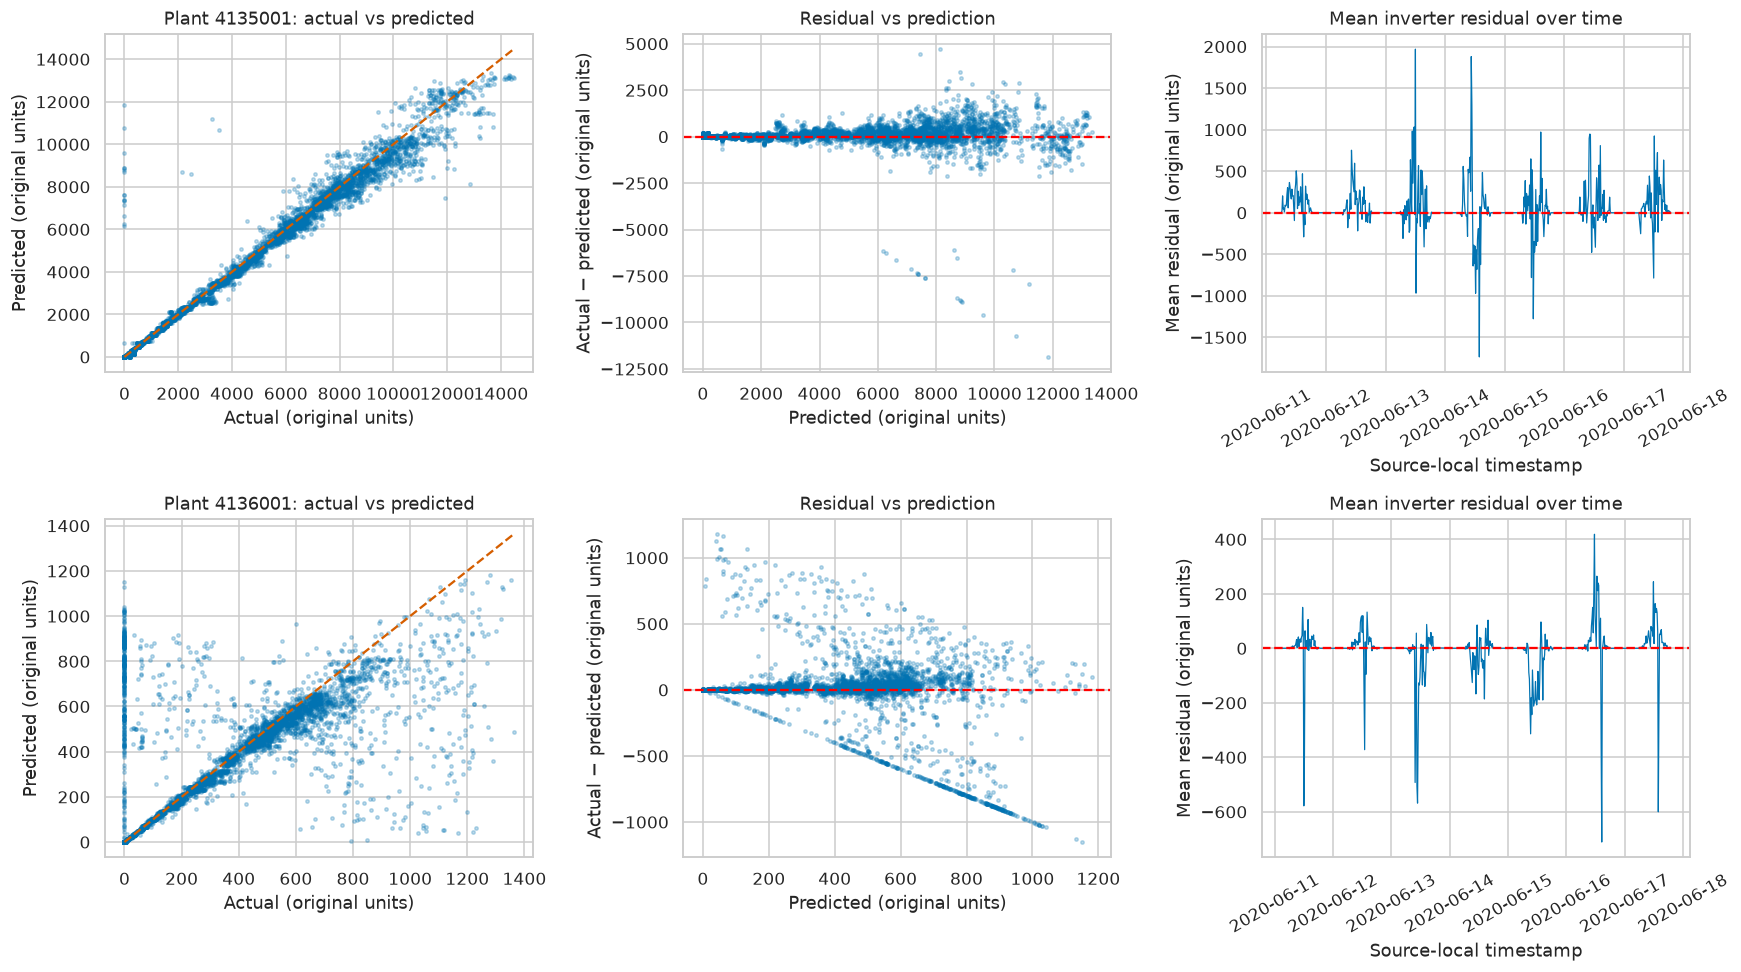

,plant,contiguous_pairs,pooled_within_inverter_lag1_corr
0,4135001,7920,0.5956
1,4136001,8184,0.7708


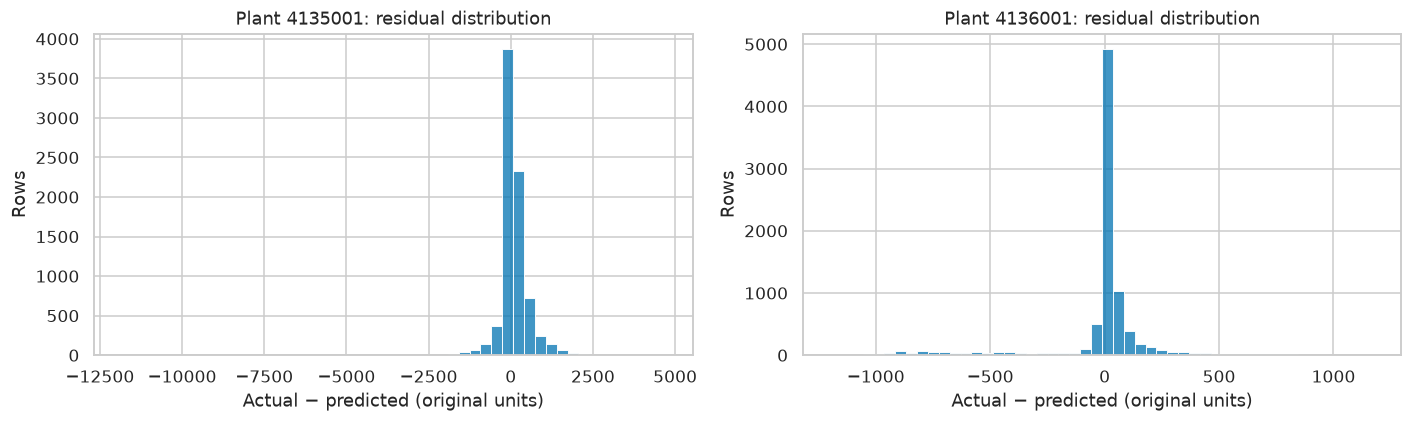

,PLANT_ID,INVERTER_ID,DATE_TIME,IRRADIATION,actual,predicted,residual
8602,4135001,1BY6WEcLGh8j5v7,2020-06-14 13:45:00,0.9066,0.0000,"11,853.4797","-11,853.4797"
8613,4135001,bvBOhCH3iADSZry,2020-06-14 13:45:00,0.9066,0.0000,"11,381.3366","-11,381.3366"
8657,4135001,bvBOhCH3iADSZry,2020-06-14 14:00:00,1.2217,0.0000,"10,748.4025","-10,748.4025"
8646,4135001,1BY6WEcLGh8j5v7,2020-06-14 14:00:00,1.2217,0.0000,"10,721.3783","-10,721.3783"
8514,4135001,1BY6WEcLGh8j5v7,2020-06-14 13:15:00,0.7344,0.0000,"9,741.4302","-9,741.4302"
8525,4135001,bvBOhCH3iADSZry,2020-06-14 13:15:00,0.7344,0.0000,"9,610.2465","-9,610.2465"
8558,4135001,1BY6WEcLGh8j5v7,2020-06-14 13:30:00,0.7278,0.0000,"9,117.1371","-9,117.1371"
8162,4135001,1BY6WEcLGh8j5v7,2020-06-14 11:15:00,0.6502,0.0000,"8,881.1000","-8,881.1000"
8569,4135001,bvBOhCH3iADSZry,2020-06-14 13:30:00,0.7278,0.0000,"8,863.4782","-8,863.4782"
8206,4135001,1BY6WEcLGh8j5v7,2020-06-14 11:30:00,0.6622,0.0000,"8,811.4457","-8,811.4457"


**Interpretasi diagnosis:** periksa bias per pembangkit, galat pada cahaya rendah atau daya puncak, dan residual yang menetap tanpa mensyaratkan distribusi normal. Korelasi tertunda satu interval hanya memakai pasangan 15 menit berurutan dalam inverter yang sama; ketergantungan waktu membuat ketidakpastian dengan asumsi baris independen menjadi menyesatkan. Galat ekstrem dipertahankan, bukan dihapus setelah pemeriksaan data uji. Diagnosis data uji mendasari keterbatasan dan penelitian lanjutan, bukan pemilihan model baru dalam eksekusi ini.

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
autocorr_rows = []
for row, (plant, part) in enumerate(test_report.groupby('PLANT_ID')):
    sample = part.sample(min(5000, len(part)), random_state=SEED)
    lo = min(part.actual.min(), part.predicted.min())
    hi = max(part.actual.max(), part.predicted.max())
    axes[row, 0].scatter(sample.actual, sample.predicted, s=5, alpha=.25)
    axes[row, 0].plot([lo, hi], [lo, hi], 'r--')
    axes[row, 0].set(title=f'Plant {plant}: actual vs predicted', xlabel='Actual (original units)',
                      ylabel='Predicted (original units)')
    axes[row, 1].scatter(sample.predicted, sample.residual, s=5, alpha=.25)
    axes[row, 1].axhline(0, color='red', linestyle='--')
    axes[row, 1].set(title='Residual vs prediction', xlabel='Predicted (original units)',
                      ylabel='Actual − predicted (original units)')
    timeline = part.groupby('DATE_TIME').residual.mean()
    axes[row, 2].plot(timeline.index, timeline.values, linewidth=.8)
    axes[row, 2].axhline(0, color='red', linestyle='--')
    axes[row, 2].tick_params(axis='x', rotation=30)
    axes[row, 2].set(title='Mean inverter residual over time', xlabel='Source-local timestamp',
                      ylabel='Mean residual (original units)')
    temp = part.sort_values(['INVERTER_ID', 'DATE_TIME']).copy()
    temp['prev_residual'] = temp.groupby('INVERTER_ID').residual.shift()
    temp['prev_time'] = temp.groupby('INVERTER_ID').DATE_TIME.shift()
    continuous = temp.DATE_TIME.sub(temp.prev_time).eq(pd.Timedelta(minutes=15))
    autocorr_rows.append({'plant': plant, 'contiguous_pairs': int(continuous.sum()),
        'pooled_within_inverter_lag1_corr': temp.loc[continuous, ['residual', 'prev_residual']].corr().iloc[0, 1]})
save_plot('final_test_diagnostics')
show_table(pd.DataFrame(autocorr_rows), 'test_residual_autocorrelation')
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, (plant, part) in zip(axes, test_report.groupby('PLANT_ID')):
    sns.histplot(part.residual, bins=50, ax=ax)
    ax.set(title=f'Plant {plant}: residual distribution', xlabel='Actual − predicted (original units)', ylabel='Rows')
save_plot('test_residual_histogram')
show_table(test_report.nlargest(10, 'abs_error')[['PLANT_ID', 'INVERTER_ID', 'DATE_TIME',
    'IRRADIATION', 'actual', 'predicted', 'residual']], 'largest_test_errors')
note('**Interpretasi diagnosis:** periksa bias per pembangkit, galat pada cahaya rendah atau daya puncak, '
    'dan residual yang menetap tanpa mensyaratkan distribusi normal. Korelasi tertunda satu interval '
    'hanya memakai pasangan 15 menit berurutan dalam inverter yang sama; ketergantungan waktu '
    'membuat ketidakpastian dengan asumsi baris independen menjadi menyesatkan. Galat ekstrem '
    'dipertahankan, bukan dihapus setelah pemeriksaan data uji. Diagnosis data uji mendasari '
    'keterbatasan dan penelitian lanjutan, bukan pemilihan model baru dalam eksekusi ini.')

## 11. Interpretasi model

Interpretasi bersifat deskriptif setelah pemilihan dikunci. Tingkat kepentingan bawaan
model pohon memiliki bias pemisahan dan jumlah kategori; besar koefisien linear
bergantung pada penskalaan dan korelasi fitur. Tingkat kepentingan melalui permutasi
di bawah menggunakan **MAE negatif**, sehingga kenaikan galat yang positif menunjukkan
informasi yang berguna untuk prediksi. Pengulangan permutasi menggambarkan sensitivitas
terhadap pengacakan, bukan interval kepercayaan kemampuan generalisasi.

Sensor yang berkorelasi dan fitur turunan deterministik dapat berbagi atau saling
menggantikan informasi; mengacak satu fitur dapat menghasilkan kombinasi tidak realistis.
Tingkat kepentingan maupun koefisien bukan efek kausal atau persentase variasi target yang
dijelaskan. Grafik ketergantungan parsial (PDP) tidak digunakan karena selisih temperatur
dan fitur interaksi terkait secara matematis, sehingga perubahan masing-masing secara
independen dapat menyesatkan. Identitas inverter dapat menyerap pola daya rendah kronis;
residual kecil tidak membuktikan inverter sehat.

### Interpretasi hasil eksekusi

Penyetelan Random Forest mengubah MAE validasi silang dari sekitar 294,84 menjadi 290,62
(perbaikan 1,43%). Kandidat Gradient Boosting hasil pencarian lebih buruk daripada
pengaturan awalnya, sekitar 354,05 dibandingkan 294,00. Aturan MAE validasi silang
terendah memilih Random Forest hasil penyetelan, tetapi keunggulan kecil dibandingkan
variasi antar lipatan tidak membuktikan keunggulan yang signifikan secara statistik.

Keunggulan model terpilih terhadap Gradient Boosting awal hanya sekitar 3,38 satuan
MAE validasi silang (1,15%). Pemilihan mengikuti objective yang telah ditentukan,
bukan bukti bahwa algoritma tersebut secara umum lebih unggul. Representasi linear
yang diuji bersifat aditif: one-hot pembangkit mengubah intersep, tetapi tidak memberi
kemiringan cuaca–daya tersendiri untuk setiap pembangkit. Interaksi pembangkit–cuaca
atau model linear per pembangkit dapat menjadi pembanding penelitian berikutnya,
dengan validasi baru; keduanya tidak ditambahkan setelah melihat test pada penelitian ini.

Pembanding rata-rata per pembangkit menghasilkan MAE test sekitar 1.661,95 dibandingkan
3.070,50 untuk rata-rata gabungan. Penurunan MAE model final sekitar 88,21% terhadap
pembanding per pembangkit, atau 93,62% terhadap rata-rata gabungan. Persentase harus
selalu menyebut pembandingnya. Angka pelengkap ini dihitung setelah test pernah dilihat
dan tidak dipakai untuk memilih ulang model atau menyatakan evaluasi independen baru.

MAE CV sekitar 290,62 dan MAE test sekitar 196,02 berasal dari periode serta komposisi
pengamatan yang berbeda; selisih keduanya bukan ukuran manfaat penyetelan. Perbaikan
penyetelan dihitung dari default dan tuned pada fold yang sama. MAE test gabungan
memberi bobot sama pada seluruh baris test, sedangkan objective CV merata-ratakan
MAE tiap fold. R² gabungan bukan rata-rata R² per pembangkit dan bukan persentase
akurasi; nilainya bergantung pada variasi target, termasuk perbedaan antarplant.
Kolom CV_R2 hanya merangkum rata-rata R² antarfold sebagai bukti pendukung, bukan
R² dari seluruh prediksi yang digabungkan.

R² gabungan pada data uji sekitar 0,979, sedangkan **R² Plant 1 sebesar 0,964 dan R²
Plant 2 hanya 0,390**. MAE relatif terhadap rata-rata target data pengembangan masing-masing
pembangkit sekitar 5,04% dan 23,08%; ini MAE yang dinormalisasi, bukan MAPE per baris.
Karena itu, Plant 2 memerlukan kehati-hatian lebih besar meskipun MAE dalam satuan
absolutnya lebih kecil. Grafik aktual-prediksi menunjukkan ketidaksesuaian besar pada
daya aktual mendekati nol dan sebaran lebih lebar pada Plant 2. Pengamatan tersebut
merupakan kandidat inspeksi, bukan kerusakan berlabel. Korelasi residual tertunda satu
interval pada pengamatan berurutan sekitar 0,596 dan 0,771 menunjukkan pola menetap;
asumsi residual normal atau saling independen tidak tepat.

PLANT_ID memiliki sensitivitas permutasi gabungan terbesar, mencerminkan perbedaan
skala yang besar. Mengacak pembangkit tanpa mengubah ID inverter juga menciptakan
kombinasi identitas yang tidak konsisten; besarnya tidak dapat diperlakukan sebagai
efek operasional tersendiri. IRRADIATION dan kuadratnya berbagi informasi prediktif,
sehingga kontribusinya bukan penguraian efek kausal yang dapat dijumlahkan. Diagnosis ini
mendukung pelaporan terpisah per pembangkit, verifikasi satuan, dan uji coba dengan
pemeriksaan operator sebelum mempertimbangkan otomatisasi operasional.

,feature,importance
9,category__PLANT_ID_4136001,0.3629
0,numeric__IRRADIATION,0.2883
7,numeric__IRR_SQUARED,0.2233
8,category__PLANT_ID_4135001,0.1145
1,numeric__AMBIENT_TEMPERATURE,0.0018
5,numeric__TEMP_GAP,0.0014
3,numeric__HOUR_SIN,0.0011
6,numeric__IRR_TEMP_INTERACTION,0.0011
2,numeric__MODULE_TEMPERATURE,0.0010
4,numeric__HOUR_COS,0.0007


,feature,MAE_increase_mean,permutation_SD
8,PLANT_ID,"1,999.7178",29.5540
0,IRRADIATION,916.3710,17.4928
7,IRR_SQUARED,783.1819,12.8700
3,HOUR_SIN,15.8002,2.0347
6,IRR_TEMP_INTERACTION,14.5988,0.6938
5,TEMP_GAP,8.6405,0.7555
9,INVERTER_ID,6.4968,2.4790
4,HOUR_COS,5.9783,0.2531
2,MODULE_TEMPERATURE,0.9925,0.3313
1,AMBIENT_TEMPERATURE,-2.3547,0.3582


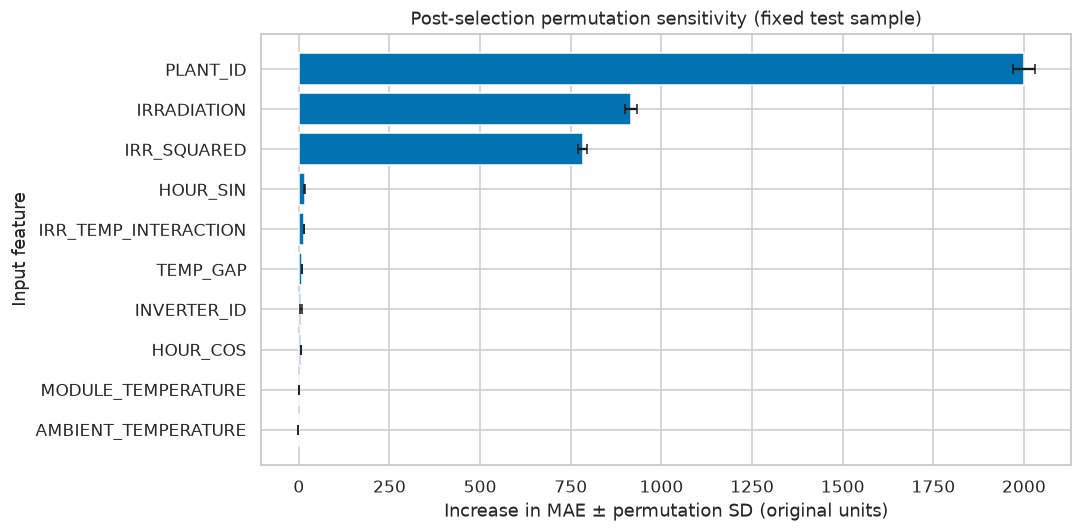

Fitur dengan sensitivitas permutasi tertinggi pada eksekusi ini: **PLANT_ID**, rata-rata kenaikan MAE 1,999.718. Tidak ada fitur atau parameter yang diubah setelah diagnosis ini.

In [13]:
estimator = final_model.named_steps['model']
transformed_names = final_model.named_steps['prep'].get_feature_names_out()
if hasattr(estimator, 'feature_importances_'):
    builtin = pd.DataFrame({'feature': transformed_names, 'importance': estimator.feature_importances_})
    show_table(builtin.sort_values('importance', ascending=False).head(15), 'model_builtin_importance')
elif hasattr(estimator, 'coef_'):
    builtin = pd.DataFrame({'feature': transformed_names, 'coefficient': estimator.coef_})
    builtin['absolute_coefficient'] = builtin.coefficient.abs()
    show_table(builtin.sort_values('absolute_coefficient', ascending=False).head(15), 'model_coefficients')
else:
    note('Estimator terpilih adalah model acuan konstan; kontribusi fitur yang dipelajari tidak tersedia.')

# Fixed diagnostic sampling only; full test metrics above use every eligible row.
sample_idx = test_report.sample(min(3000, len(test_report)), random_state=SEED).index
perm = permutation_importance(final_model, X_test.loc[sample_idx], y_test.loc[sample_idx],
    scoring='neg_mean_absolute_error', n_repeats=5, random_state=SEED, n_jobs=1)
perm_table = pd.DataFrame({'feature': FEATURES, 'MAE_increase_mean': perm.importances_mean,
                           'permutation_SD': perm.importances_std}).sort_values('MAE_increase_mean', ascending=False)
show_table(perm_table, 'permutation_importance')
fig, ax = plt.subplots(figsize=(10, 5))
ax.barh(perm_table.feature, perm_table.MAE_increase_mean, xerr=perm_table.permutation_SD, capsize=3)
ax.invert_yaxis()
ax.set(title='Post-selection permutation sensitivity (fixed test sample)',
    xlabel='Increase in MAE ± permutation SD (original units)', ylabel='Input feature')
save_plot('permutation_importance')
note(f'Fitur dengan sensitivitas permutasi tertinggi pada eksekusi ini: **{perm_table.iloc[0].feature}**, '
     f'rata-rata kenaikan MAE {perm_table.iloc[0].MAE_increase_mean:,.3f}. '
     'Tidak ada fitur atau parameter yang diubah setelah diagnosis ini.')

## 12. Temuan dan rekomendasi tindakan

Prototipe di bawah menerapkan aturan yang telah dikunci dari data pengembangan pada
seluruh inverter dalam data uji. Tiga interval berurutan mewakili 45 menit pembacaan
interval, dengan rentang 30 menit antar waktu pengamatan. Jeda atau waktu yang hilang
mengulang perhitungan urutan. Yang dihitung adalah episode pemeriksaan terpisah, bukan
setiap baris peringatan lanjutan sebagai inspeksi baru. Beban peringatan dapat diukur;
tingkat positif palsu, sensitivitas deteksi kerusakan, dan waktu henti yang dicegah
memerlukan label yang tidak tersedia di sini.

Eksekusi menghasilkan 3 episode pemeriksaan pada Plant 1 dan 10 pada Plant 2 selama
7 hari uji dengan ambang yang dikunci. Angka ini menentukan antrean pemeriksaan
operator, bukan jumlah inverter rusak. Ambang selisih, sekitar 1.577 dan 917 satuan
asli, tergolong tinggi terutama terhadap daya Plant 2; penyimpangan yang lebih kecil
dapat terlewat. Tanpa label inspeksi, penelitian ini belum dapat mengukur konsekuensi
pemilihan ambang terhadap sensitivitas deteksi.

Kecocokan penggabungan cuaca mencapai 99,994% dan 100%, tetapi audit interval data daya
tetap menemukan 3.026 dan 4.110 interval inverter yang tidak tercatat antara waktu awal
dan akhir tiap sumber. Salah satu inverter Plant 2 hanya memiliki cakupan sekitar 72,15%
berdasarkan rentang tersebut. Pemantauan kualitas data perlu mencakup waktu pengamatan
yang hilang, bukan hanya nilai kosong atau tingkat kecocokan penggabungan cuaca.

In [14]:
alerts = test_report.merge(thresholds, on='PLANT_ID', how='left', validate='many_to_one')
alerts = alerts.sort_values(['PLANT_ID', 'INVERTER_ID', 'DATE_TIME']).reset_index(drop=True)
alerts['candidate_alert'] = (alerts.gap.gt(alerts.gap_threshold) & alerts.gap.gt(0)
                            & alerts.predicted.ge(alerts.min_expected))
alerts['streak'] = 0
for _, idx in alerts.groupby(['PLANT_ID', 'INVERTER_ID']).groups.items():
    streak, prev = 0, None
    for i in idx:
        row = alerts.loc[i]
        adjacent = prev is not None and row.DATE_TIME - prev == pd.Timedelta(minutes=15)
        streak = (streak + 1 if adjacent else 1) if row.candidate_alert else 0
        alerts.loc[i, 'streak'] = streak
        prev = row.DATE_TIME
alerts['persistent_alert'] = alerts.streak.ge(3)
alerts['new_episode'] = alerts.streak.eq(3)
alert_summary = alerts.groupby('PLANT_ID').agg(rows=('actual', 'size'),
    candidate_rows=('candidate_alert', 'sum'), persistent_rows=('persistent_alert', 'sum'),
    review_episodes=('new_episode', 'sum'), days=('DATE', 'nunique'))
alert_summary['persistent_row_pct'] = 100 * alert_summary.persistent_rows / alert_summary.rows
alert_summary['episodes_per_day'] = alert_summary.review_episodes / alert_summary.days
show_table(alert_summary.reset_index(), 'test_alert_workload')
show_table(alerts.groupby(['PLANT_ID', 'INVERTER_ID'], as_index=False).agg(
    candidate_rows=('candidate_alert', 'sum'), persistent_rows=('persistent_alert', 'sum'),
    review_episodes=('new_episode', 'sum')).sort_values('review_episodes', ascending=False),
    'test_alerts_by_inverter')
alerts.to_csv(OUT / 'test_alert_predictions.csv', index=False)

findings = pd.DataFrame([
    {'finding': 'Model accuracy on newer dates',
     'evidence': f'{chosen["candidate"]}; test MAE={final_scores.iloc[0].MAE:.3f}, '
                 f'RMSE={final_scores.iloc[0].RMSE:.3f}; reduction vs pooled mean={test_gain:.2f}%; '
                 f'vs plant mean (supplemental)={plant_baseline_gain:.2f}%',
     'action': 'Use actual-vs-expected monitoring in shadow mode, reviewed by operator',
     'stakeholder': 'Operations Manager', 'value': 'Condition-aware prioritization',
     'limitation': 'Horizon 0, known plants, not failure prediction'},
    {'finding': 'Inter-plant measurement scale differs',
     'evidence': '; '.join(f'{p}: median DC/AC={v:.3f}' for p, v in ratios.items()),
     'action': 'Verify units, ratings and sensor mappings before common physical thresholds',
     'stakeholder': 'Plant engineer / data team', 'value': 'Avoid misleading cross-site priorities',
     'limitation': 'Ratio is a diagnostic, not proof of a correction factor'},
    {'finding': 'Sensor availability constrains monitoring coverage',
     'evidence': '; '.join(f'{p}: weather match={r.weather_match_pct:.2f}%'
                           for p, r in join_audit.iterrows()),
     'action': 'Log sensor availability and missing intervals; route unavailable periods to data-quality review',
     'stakeholder': 'Data/SCADA team', 'value': 'Distinguish unavailable monitoring from low output',
     'limitation': 'Generation missing intervals also reduce observable coverage'},
    {'finding': 'Persistent gap produces a concrete review workload',
     'evidence': '; '.join(f'{p}: {int(r.review_episodes)} episodes / {int(r.days)} days'
                           for p, r in alert_summary.iterrows()),
     'action': 'Pilot a review queue with capacity agreed with operations; attach inspection outcomes',
     'stakeholder': 'Maintenance supervisor', 'value': 'Measure feasibility before production rollout',
     'limitation': 'Unlabeled alerts are not confirmed faults or estimated false alarms'}])
show_table(findings, 'evidence_action_matrix')
note('**Rekomendasi 1:** Tim operasional memprioritaskan Plant 1 untuk uji coba antrean inspeksi berbasis residual, '
     'karena R² dan MAE relatifnya lebih baik; Plant 2 memerlukan investigasi tambahan atas '
     'ketidaksesuaian daya nol sebelum penerapan lebih luas. Uji coba dilakukan '
     'dengan pemeriksaan manusia, aturan ambang yang dikunci, dan beban kerja terukur di atas. '
     'Mulai dengan pemantauan tanpa tindakan otomatis; catat hasil inspeksi, waktu pemeriksaan, '
     'dan masalah terkonfirmasi sebelum mengotomatisasi pemeliharaan.'
     '\n\n**Rekomendasi 2:** Tim teknis/data pembangkit memverifikasi satuan dan kapasitas peralatan, '
     'memantau cakupan sensor/data daya yang hilang, serta menjaga laporan galat dan ambang '
     'terpisah per pembangkit. Tindakan ini mengikuti temuan skala dan ketersediaan data, '
     'tanpa mengasumsikan pembacaan mentah sebanding secara fisik. Cakupan, kapasitas pemeriksaan, '
     'dan toleransi galat perlu disepakati sebelum persetujuan penerapan.')

,PLANT_ID,rows,candidate_rows,persistent_rows,review_episodes,days,persistent_row_pct,episodes_per_day
0,4135001,8096,58,25,3,7,0.3088,0.4286
1,4136001,8492,61,20,10,7,0.2355,1.4286


,PLANT_ID,INVERTER_ID,candidate_rows,persistent_rows,review_episodes
42,4136001,xMbIugepa2P7lBB,7,2,2
26,4136001,IQ2d7wF4YD8zU1Q,7,2,2
0,4135001,1BY6WEcLGh8j5v7,16,12,1
11,4135001,bvBOhCH3iADSZry,15,12,1
36,4136001,mqwcsP2rE7J0TFp,3,1,1
29,4136001,Mx2yZCDsyf6DPfv,16,6,1
32,4136001,Qf4GUc1pJu5T6c6,9,3,1
30,4136001,NgDl19wMapZy17u,5,1,1
20,4135001,zBIq5rxdHJRwDNY,3,1,1
22,4136001,4UPUqMRk7TRMgml,4,1,1


,finding,evidence,action,stakeholder,value,limitation
0,Model accuracy on newer dates,"Random Forest [tuned]; test MAE=196.019, RMSE=...",Use actual-vs-expected monitoring in shadow mo...,Operations Manager,Condition-aware prioritization,"Horizon 0, known plants, not failure prediction"
1,Inter-plant measurement scale differs,4135001: median DC/AC=10.222; 4136001: median ...,"Verify units, ratings and sensor mappings befo...",Plant engineer / data team,Avoid misleading cross-site priorities,"Ratio is a diagnostic, not proof of a correcti..."
2,Sensor availability constrains monitoring cove...,4135001: weather match=99.99%; 4136001: weathe...,Log sensor availability and missing intervals;...,Data/SCADA team,Distinguish unavailable monitoring from low ou...,Generation missing intervals also reduce obser...
3,Persistent gap produces a concrete review work...,4135001: 3 episodes / 7 days; 4136001: 10 epis...,Pilot a review queue with capacity agreed with...,Maintenance supervisor,Measure feasibility before production rollout,Unlabeled alerts are not confirmed faults or e...


**Rekomendasi 1:** Tim operasional memprioritaskan Plant 1 untuk uji coba antrean inspeksi berbasis residual, karena R² dan MAE relatifnya lebih baik; Plant 2 memerlukan investigasi tambahan atas ketidaksesuaian daya nol sebelum penerapan lebih luas. Uji coba dilakukan dengan pemeriksaan manusia, aturan ambang yang dikunci, dan beban kerja terukur di atas. Mulai dengan pemantauan tanpa tindakan otomatis; catat hasil inspeksi, waktu pemeriksaan, dan masalah terkonfirmasi sebelum mengotomatisasi pemeliharaan.

**Rekomendasi 2:** Tim teknis/data pembangkit memverifikasi satuan dan kapasitas peralatan, memantau cakupan sensor/data daya yang hilang, serta menjaga laporan galat dan ambang terpisah per pembangkit. Tindakan ini mengikuti temuan skala dan ketersediaan data, tanpa mengasumsikan pembacaan mentah sebanding secara fisik. Cakupan, kapasitas pemeriksaan, dan toleransi galat perlu disepakati sebelum persetujuan penerapan.

## 13. Implikasi bisnis, keterbatasan, dan langkah selanjutnya

**Penggunaan yang diharapkan.** Tim operasional menerima antrean pemeriksaan yang
mempertimbangkan kondisi cuaca, tim data/SCADA memantau ketersediaan sensor, dan pengawas
pemeliharaan melampirkan hasil inspeksi. Uji coba perlu mencatat waktu dan keterlambatan
masukan, prediksi, ambang, periode tanpa data, ID episode, waktu pemeriksaan, hasil,
dan biaya. Dasbor atau aplikasi terpisah tidak diwajibkan untuk penilaian ini;
tabel notebook menjadi bukti bagi alur kerja yang diusulkan.

**Penerapan.** Sepakati antarmuka akses data, keterlambatan sensor, anggaran eksekusi model,
penanggung jawab, eskalasi, dan kewenangan operator bersama staf pembangkit. Tinjau galat,
pergeseran pola per pembangkit dan kondisi iradiasi, serta beban peringatan sebelum
menentukan frekuensi pelatihan ulang. Pelatihan ulang bulanan tidak diklaim optimal.
Penerimaan uji coba memerlukan batas cakupan/galat yang disetujui pemangku kepentingan
dan jumlah episode harian yang dapat ditangani; hasil proyek tidak dianggap sebagai
sertifikasi siap produksi. Biaya integrasi dan tingkat pengembalian investasi (ROI)
belum diketahui tanpa catatan tenaga kerja, waktu henti, harga energi, dan biaya pemeliharaan.

**Keterbatasan.** Data hanya mencakup 34 hari dan dua pembangkit, tanpa validasi lintas
musim atau lokasi luar. Pembacaan sensor tingkat pembangkit digunakan bersama oleh banyak
baris inverter. Perbedaan skala target memerlukan verifikasi teknis; MAE gabungan bukan
kerugian fisik atau finansial. Lipatan kronologis dan data uji menggunakan identitas
pembangkit/inverter yang sama. Pemilihan dan pencarian memakai ulang lipatan validasi,
sehingga hasil dapat terlalu optimistis. Sensor hilang dan pembatasan pengamatan siang
membatasi cakupan; prediksi belum divalidasi pada iradiasi hilang atau malam hari.
Korelasi dan fitur turunan mempersulit penentuan kontribusi fitur. ID inverter dapat
menormalkan kinerja rendah kronis. Tidak tersedia label pemeliharaan, tanggal kegagalan,
peringatan palsu terkonfirmasi, kapasitas peralatan, atau prakiraan cuaca. Hubungan
statistik tidak membuktikan sebab-akibat. Sumber publik mengidentifikasi pengunggah,
tetapi bukan pemilik fasilitas asli. Keunikan dataset dan tidak digunakannya dataset
UTS telah dikonfirmasi tim pada 14 Oktober 2026; bukti registrasi belum diperiksa
secara independen dalam notebook ini.

**Langkah selanjutnya.** Verifikasi metadata, lisensi, dan satuan sumber; kumpulkan data
sedikitnya satu tahun beserta kapasitas peralatan dan catatan pemeliharaan; validasi
antrean dengan hasil pemeriksaan operator serta biaya; dan evaluasi penerapan lintas
pembangkit secara terpisah. Peramalan daya hari berikutnya memerlukan waktu asal dan
horizon prediksi baru, prakiraan cuaca yang tersedia saat prediksi dibuat termasuk
estimasi temperatur modul yang dapat dipertanggungjawabkan, model acuan peramalan,
serta pengujian historis sesuai horizon. Uji coba sebelum-sesudah saja tidak dapat
mengaitkan perubahan dengan pemeliharaan tanpa memperhitungkan pengaruh cuaca dan operasi.

## 14. Reproduksibilitas dan tinjauan mandiri penilaian

Notebook ini memuat seluruh 13 bagian analisis yang diwajibkan beserta bagian verifikasi.
Hash CSV mengidentifikasi versi data yang digunakan; masukan memakai satu lokasi data
relatif. Tidak diperlukan unduhan tersembunyi, login, variabel sesi sebelumnya, atau
modul eksternal proyek. Tabel dan grafik disimpan dalam `outputs/` untuk digunakan
kembali pada slide. Pelatihan model memakai seluruh baris yang memenuhi syarat;
pengambilan sampel tetap hanya digunakan untuk grafik dan interpretasi setelah seleksi.
Eksekusi notebook menjalankan pemeriksaan di bawah secara otomatis. Verifikasi kernel
bersih dan review rubrik dicatat terpisah dalam `NOTEBOOK_REVIEW.md`.

**Batas pengerjaan:** tugas ini mencakup notebook, data pendukung, dan reproduksibilitas.
Pengumpulan lengkap juga memerlukan slide akhir, kontribusi aktual tiap anggota, arsip
bukti registrasi (pendaftaran, keunikan, dan tidak digunakannya dataset UTS telah
dikonfirmasi tim), partisipasi panel pemangku kepentingan, dan penguasaan saat wawancara.
Hal-hal tersebut tidak dibuktikan oleh eksekusi notebook. Tenggat: 19 Oktober 2026,
20.00 WIB; wawancara teknis: 26 Oktober 2026. Kelompok 7 menjadi presenter urutan ketiga
pada Pertemuan 15 dengan panel Kelompok 3, serta menjadi panel untuk Kelompok 3 pada Pertemuan 14.

In [15]:
checks = {
    'four exact CSV files loaded': len(manifest) == 4,
    'minimum tabular size and predictors': len(panel) >= 1000 and len(FEATURES) >= 5,
    'no target/proxy in features': not set(FEATURES) & {'DC_POWER','AC_POWER','DAILY_YIELD','TOTAL_YIELD'},
    'no join multiplication': len(merged) == len(gen),
    'strict chronological holdout': dev.DATE_TIME.max() < test.DATE_TIME.min(),
    'five grouped-date folds': len(cv_splits) == 5,
    'all required model families': {'Linear Regression','Random Forest','Gradient Boosting'} <= set(models),
    'two strongest non-baseline tuned': set(searches) == set(selected) and len(searches) == 2,
    'at least two tuning parameters each': all(len(spaces[n]) >= 2 for n in selected),
    'test predictions finite': np.isfinite(pred_final).all(),
    'three findings and two recommendations': len(findings) >= 3,
    'thresholds locked from development': thresholds.oof_rows.sum() == len(selected_oof),
    'per-plant test reporting': len(plant_scores) == dev.PLANT_ID.nunique()
}
checks['supplemental baseline on identical five folds'] = len(plant_base_folds) == len(cv_splits)
checks['consistent sample SD for tuning comparison'] = tuning.SD_ddof.eq(1).all()
checks['supplemental baseline excluded from model selection'] = not lock['supplemental_baseline_used_for_selection']
checks = {key: bool(value) for key, value in checks.items()}
assert all(checks.values()), checks
show_table(pd.DataFrame({'check': list(checks), 'passed': list(checks.values())}), 'verification_checks')
summary = {'selected_model': chosen['candidate'], 'test': final_scores.to_dict('records'),
    'test_MAE_reduction_vs_baseline_pct': float(test_gain),
    'test_MAE_reduction_vs_plant_baseline_pct': float(plant_baseline_gain),
    'evaluation_status': 'reproduction_after_test_exposure',
    'statistical_reporting': {'fold_weighting': 'equal_folds', 'SD_ddof': 1,
        'confidence_intervals_or_significance_claims': False},
    'rows_generation': len(gen), 'rows_daytime': len(panel), 'rows_development': len(dev),
    'rows_test': len(test), 'days_development': dev.DATE.nunique(), 'days_test': test.DATE.nunique(),
    'tuned_models': selected, 'run_seconds': time.perf_counter() - RUN_START,
    'environment': environment, 'checks': checks, 'utc_completed': datetime.now(timezone.utc).isoformat()}
(OUT / 'run_summary.json').write_text(json.dumps(summary, indent=2, default=str))
print(f'Completed full notebook in {summary["run_seconds"]:.1f} seconds; all checks passed.')
note('**Batas review:** keberhasilan pemeriksaan komputasi menjadi bukti untuk notebook, '
     'bukan jaminan nilai. Registrasi, kelayakan sumber asli, hak penggunaan, penguasaan '
     'individual, dan kelengkapan pengumpulan tugas tetap memerlukan bukti tersendiri.')

,check,passed
0,four exact CSV files loaded,True
1,minimum tabular size and predictors,True
2,no target/proxy in features,True
3,no join multiplication,True
4,strict chronological holdout,True
5,five grouped-date folds,True
6,all required model families,True
7,two strongest non-baseline tuned,True
8,at least two tuning parameters each,True
9,test predictions finite,True


Completed full notebook in 365.7 seconds; all checks passed.


**Batas review:** keberhasilan pemeriksaan komputasi menjadi bukti untuk notebook, bukan jaminan nilai. Registrasi, kelayakan sumber asli, hak penggunaan, penguasaan individual, dan kelengkapan pengumpulan tugas tetap memerlukan bukti tersendiri.